# DX703 Final Project Milestone: Data Exploration and Baseline Modeling

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**


## Purpose and scope

This is the **first of two project submissions**. Choose **one** classification dataset—**Food-101** (images) or **HuffPost News Category** (text)—and carry it from initial exploration through a reproducible **baseline model**.

In this milestone you will:

1. Explore both datasets briefly; select and investigate one (**10 pts**).
2. Frame its classification problem, challenges, and evaluation strategy (**15 pts**).
3. Clean and preprocess your data and create reproducible train/validation/test splits (**30 pts**).
4. Train and evaluate a simple baseline using **training and validation data only** (**30 pts**).

**The later final submission** will cover a more capable custom model, a pretrained/transfer-learning model, comparison and selection, a refined final model, and the final technical report. Details of that submission will be posted separately.

### Important conventions

- Retain your chosen dataset for the entire project. Remove the unused dataset's starter cells **after** exploring both.
- Use a fixed random seed, state all data-selection choices and important hyperparameters, and keep the notebook runnable from top to bottom.
- You may use a documented, reproducible subset for experiments if computing resources are limited; explain its size and selection process. Do not represent subset performance as full-dataset performance.
- **Keep the test set untouched in this milestone.** Select models and discuss baseline performance using *validation* results. Save test-set evaluation for the final submission.
- Write each graded explanation in its designated Python string answer variable (`a1a`, `a1b`, etc.). Do not modify the following **Graded Answer** print cells. You may add code cells, plots, or comments as necessary. Follow the approximate word-count guidelines in each problem (100–150 words for Problems 1, 3, and 4; 75–125 words for Problem 2).
- Include an AI-use disclosure at the end in accordance with CDS policy.


### Grading — 85 points total

| Problem | Grading basis | Points |
|---|---|---:|
| 1. Choose the Dataset | 5 questions × 2 pts, including supporting code, tables, and plots | **10** |
| 2. Frame the Problem | 5 questions × 3 pts, including supporting evidence | **15** |
| 3. Data Preparation and Splits | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| 4. Baseline Model | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| **Total** | | **85** |

**How your work will be assessed:** For Problems 1–2, each question will be assessed as a whole, including your written response and the supporting code, tables, or plots. For Problems 3–4, programming and written answers receive separate point allocations.

Programming will be assessed primarily for **correctness and completeness**, with attention to reproducibility, organization, and clarity. Written answers should accurately explain *your own implementation and results*, referring to specific evidence from the notebook. Code may be reviewed and tested, so explanations alone do not earn programming credit. Your submitted notebook must run from beginning to end without errors.

**Use of AI in grading:** We will use AI tools to assist with reviewing code, evaluating written responses, and identifying possible errors or omissions. However, **AI will not make final grading decisions. Every proposed point deduction will be reviewed by a human grader before it is applied.** Human graders retain responsibility for determining and assigning final scores.

In [1]:
!pip install -q datasets tensorflow scikit-learn pandas matplotlib spacy tqdm pyarrow

In [2]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import time
import math
import random
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
# import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- NLP / Tokenization
import spacy                         # used for text preprocessing (HuffPost)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
)

# --- (Optional) Classical ML Baseline Tools
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score


# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)   # sets Python, NumPy, and TensorFlow seeds

# Utility: format seconds as HH:MM:SS

"""
Example usage to time your code:

start_time = time.time()
# ... your code here ...
print("Execution Time:", format_hms(time.time() - start_time))
"""

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


I0000 00:00:1794762731.547251    2711 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794762742.350718    2711 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794762751.016591    2711 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
# If needed (in a new env):
# !pip install -U datasets pillow

In [4]:
# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel

/usr/local/python/3.14.2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---

### Dataset Two (Text): HuffPost Dataset

#### **Load HuffPost (headline + summary + category)**

**Note:** This loads a **Hugging Face `Dataset`**, not a NumPy array or Pandas DataFrame.
- Each record is a **dictionary** with fields such as `"headline"`, `"short_description"`, and `"category"`.
- You can access columns by name (e.g., `huff["headline"]`) and check dataset size with `len(huff)`.
- Treat it as a table of text fields — you’ll handle tokenization and vectorization later during preprocessing.
- The typical BERT-compatible separator is used to construct the sample texts

        `headline [SEP] short-description`



In [5]:
# JSON mirror that preserves fields: headline, short_description, category, authors, link, date
URL = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff_all = load_dataset("json", data_files=URL, split="train")

print(huff_all)
print("Columns:", huff_all.column_names)
print("Total rows:", len(huff_all))

Dataset({
    features: ['category', 'headline', 'authors', 'link', 'short_description', 'date'],
    num_rows: 200853
})
Columns: ['category', 'headline', 'authors', 'link', 'short_description', 'date']
Total rows: 200853


#### **Quick sanity checks (peek at a row)**

In [6]:
ex = huff_all[0]
print("One example:")
print("  category          :", ex.get("category"))
print("  headline          :", (ex.get("headline") or "")[:120])
print("  authors           :", (ex.get("authors") or "")[:120])
print("  short_description :", (ex.get("short_description") or "")[:120])
print("  date              :", ex.get("date"))

One example:
  category          : CRIME
  headline          : There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV
  authors           : Melissa Jeltsen
  short_description : She left her husband. He killed their children. Just another day in America.
  date              : 2018-05-26 00:00:00


#### **Print 10 random samples (combined text with separator, no truncation)**

In [7]:
# Show k random lines: "headline [SEP] short_description"

k = 10
seed = 7
rng = random.Random(seed)
idxs = rng.sample(range(len(huff_all)), k)

for i in idxs:
    ex = huff_all[i]
    print("  category          :", ex.get("category"))
    print("  headline          :", (ex.get("headline") or ""))
    print("  short_description :", (ex.get("short_description") or ""))
    print("  sample text       :", (ex.get("headline") or "")+'  [SEP]  '+ (ex.get("short_description") or ""))
    print()

  category          : ENTERTAINMENT
  headline          : Pregnant Kim Kardashian Rocks A Sheer Jumpsuit At The Airport
  short_description : Forget what you thought you knew about maternity style, because Kim's changing the game.
  sample text       : Pregnant Kim Kardashian Rocks A Sheer Jumpsuit At The Airport  [SEP]  Forget what you thought you knew about maternity style, because Kim's changing the game.

  category          : WOMEN
  headline          : How I Outran Misogyny
  short_description : "I have started running to retrain the way my brain sees my body, not as a sexual object but as a tool to get things done."
  sample text       : How I Outran Misogyny  [SEP]  "I have started running to retrain the way my brain sees my body, not as a sexual object but as a tool to get things done."

  category          : RELIGION
  headline          : A Prayer From the Mall of America
  short_description : I thank you for the Bloomington Police Department, and the Mall of America Security

#### **(Optional) Save splits to disk (reload later without re-splitting)**

We provide this in case you want to save the dataset to your local disk. Saving Food-101 splits to disk is not recommended unless you have ample local storage (it's huge!). 

In [8]:
# huff.save_to_disk("huffpost_splits")        # save
# from datasets import load_from_disk
# huff = load_from_disk("huffpost_splits")  # reload when needed

---

## Problem 1 — Choose the Dataset (10 pts)

#### Objective
In this problem, you will explore the two provided datasets and select one to use for your final project.  
Your goal is to understand the structure, content, and challenges of the dataset through basic exploratory data analysis (EDA).  
By the end of this milestone notebook, you should be able to explain what makes the dataset interesting, identify potential modeling challenges (e.g., imbalance, ambiguity, quality issues), and justify why it is a good choice for your classification project.


#### What to Do
1. **Load both datasets** and examine the outputs of the template code provided.  
   After this brief inspection, **choose one dataset for your project** and **delete the template code for the other.**  For your chosen dataset, continue with the remaining steps.

2. **Inspect** the dataset's basic properties:  
   - **Number of samples and classes:**  
     Determine how many total examples and distinct categories are present. Verify that the counts match expectations (e.g., 101 food classes or 41 news topics).  
   - **Example records or images:**  
     View several samples to understand the input format, diversity, and potential quality issues.  
     For images, note lighting or composition differences; for text, read a few headlines and summaries to see how expressive they are (done for you in template code). 
   - **Distribution of labels (check for imbalance):**  
     Plot or tabulate label frequencies to see whether some classes dominate. Imbalanced datasets can bias model training and may require special handling.  
   - **Missing or inconsistent data:**  
     Look for empty fields, unreadable images, duplicate entries, or mislabeled samples. Handle or document any issues you find.  
   - **Overlapping or ambiguous class labels:**  
     Identify categories that may not be clearly distinct—e.g., “apple pie” vs. “cheesecake,” or “POLITICS” vs. “WORLD NEWS.”  
     Ambiguity in labels can increase confusion between classes and reduce model accuracy.

3. **Visualize key aspects:**  
   Extend the template code to complete the EDA for your chosen dataset:  
   - **Images:**  
     Create visual summaries to better understand the data (some are implemented in the template code).  
     - Verify that the dataset is balanced across classes.  
     - Display a small grid of random images to check variation in appearance, composition, and background (done in template code).  
     - Compare image sizes to determine whether resizing or normalization will be needed.  
     - Examine lighting and color balance—many web-scraped photos vary widely in brightness, saturation, and white balance.  
   - **Text:**  
     Visualize class balance and linguistic properties (some implemented in the template code).  
     - Plot the number of samples per label to confirm class balance or imbalance.  
     - Compute basic text statistics such as average word count or vocabulary size.  
     - Examine examples for duplicates, near-duplicates, or entries that might fit multiple categories.  
     - *(Optional)* Generate a word-frequency plot or word cloud to highlight distinctive terms for a few classes.

4. **Answer the graded questions below.**


**P1.1 Load and inspect:** Load data and build combined text.

In [9]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 

import re
import json
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

df_raw = huff_all.to_pandas()
df_raw["headline"] = df_raw["headline"].fillna("").astype(str).str.strip()
df_raw["short_description"] = df_raw["short_description"].fillna("").astype(str).str.strip()
df_raw["text"] = (df_raw["headline"] + " [SEP] " + df_raw["short_description"]).str.strip()

print("Rows:", len(df_raw))
print("Columns:", list(df_raw.columns))
print("Distinct categories:", df_raw["category"].nunique())
display(df_raw[["category", "headline", "short_description", "date"]].head())

Rows: 200853
Columns: ['category', 'headline', 'authors', 'link', 'short_description', 'date', 'text']
Distinct categories: 41


,category,headline,short_description,date
0,CRIME,"There Were 2 Mass Shootings In Texas Last Week, But Only 1 On TV",She left her husband. He killed their children. Just another day in America.,2018-05-26
1,ENTERTAINMENT,Will Smith Joins Diplo And Nicky Jam For The 2018 World Cup's Official Song,Of course it has a song.,2018-05-26
2,ENTERTAINMENT,Hugh Grant Marries For The First Time At Age 57,The actor and his longtime girlfriend Anna Eberstein tied the knot in a civil ceremony.,2018-05-26
3,ENTERTAINMENT,Jim Carrey Blasts 'Castrato' Adam Schiff And Democrats In New Artwork,The actor gives Dems an ass-kicking for not fighting hard enough against Donald Trump.,2018-05-26
4,ENTERTAINMENT,Julianna Margulies Uses Donald Trump Poop Bags To Pick Up After Her Dog,"The ""Dietland"" actress said using the bags is a ""really cathartic, therapeutic moment.""",2018-05-26


**P1.2 Class distribution:** Articles per category.

,count,pct
category,,
POLITICS,32739,16.30
WELLNESS,17827,8.88
ENTERTAINMENT,16058,7.99
TRAVEL,9887,4.92
STYLE & BEAUTY,9649,4.80
PARENTING,8677,4.32
HEALTHY LIVING,6694,3.33
QUEER VOICES,6314,3.14
FOOD & DRINK,6226,3.10


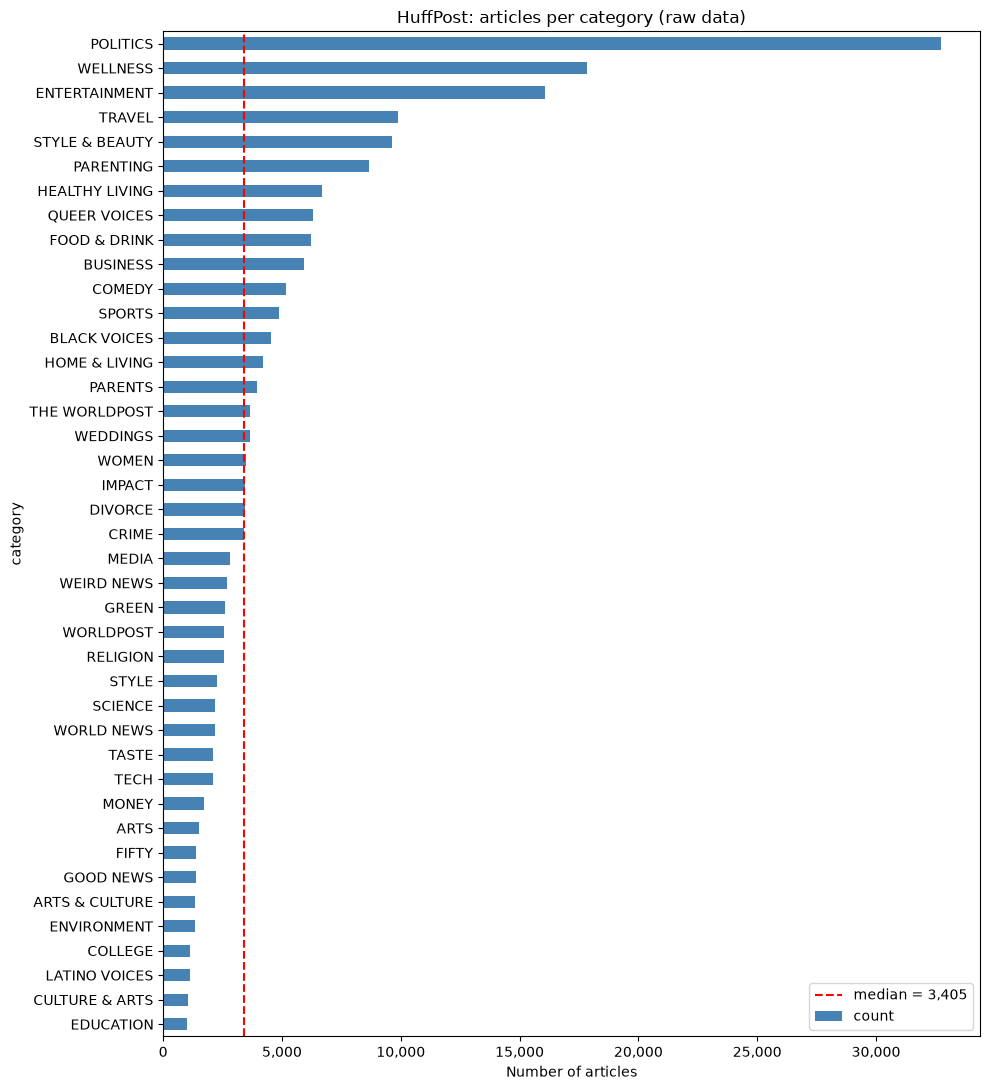

In [10]:
class_counts = df_raw["category"].value_counts()
class_table = class_counts.to_frame("count")
class_table["pct"] = (100 * class_table["count"] / class_table["count"].sum()).round(2)
display(class_table)

fig, ax = plt.subplots(figsize=(10, 11))
class_counts.sort_values().plot.barh(ax=ax, color="steelblue")
ax.axvline(class_counts.median(), color="red", linestyle="--", label=f"median = {int(class_counts.median()):,}")
ax.set_xlabel("Number of articles")
ax.set_title("HuffPost: articles per category (raw data)")
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

**P1.3 Data quality:** Empty, duplicate, and conflicting entries.

In [11]:
quality = pd.Series({
    "rows": len(df_raw),
    "empty_headline": int((df_raw["headline"] == "").sum()),
    "empty_short_description": int((df_raw["short_description"] == "").sum()),
    "both_empty": int(((df_raw["headline"] == "") & (df_raw["short_description"] == "")).sum()),
    "duplicate_links": int(df_raw["link"].duplicated().sum()),
    "duplicate_texts": int(df_raw["text"].duplicated().sum()),
    "duplicate_headlines": int(df_raw.loc[df_raw["headline"] != "", "headline"].duplicated().sum()),
    "texts_with_conflicting_labels": int((df_raw.groupby("text")["category"].nunique() > 1).sum()),
})
display(quality.to_frame("count"))

dup_examples = (df_raw[df_raw["text"].duplicated(keep=False)]
                .sort_values("text")[["category", "headline", "short_description"]]
                .head(10))
display(dup_examples)

,count
rows,200853
empty_headline,6
empty_short_description,19712
both_empty,5
duplicate_links,41
duplicate_texts,488
duplicate_headlines,1504
texts_with_conflicting_labels,15


,category,headline,short_description
196861,BLACK VOICES,'Black Love' Wedding Announcements (PHOTOS),"""Black Love"" Wedding Announcements: Getting married? Celebrating a wedding anniversary? If so, share your love with ..."
198172,BLACK VOICES,'Black Love' Wedding Announcements (PHOTOS),"""Black Love"" Wedding Announcements: Getting married? Celebrating a wedding anniversary? If so, share your love with ..."
199545,BLACK VOICES,'Black Love' Wedding Announcements (PHOTOS),"""Black Love"" Wedding Announcements: Getting married? Celebrating a wedding anniversary? If so, share your love with ..."
200115,BLACK VOICES,'Black Love' Wedding Announcements (PHOTOS),"""Black Love"" Wedding Announcements: Getting married? Celebrating a wedding anniversary? If so, share your love with ..."
196352,TRAVEL,'Riding The Dog': Coast-To-Coast By Greyhound Bus,Why would you ride on Greyhound instead of driving -- or grabbing a train or plane?
197675,TRAVEL,'Riding The Dog': Coast-To-Coast By Greyhound Bus,Why would you ride on Greyhound instead of driving -- or grabbing a train or plane?
191660,STYLE & BEAUTY,"'SNL' Skewers Tanning Mom, Asks Her For Beauty Advice On 'Weekend Update' (VIDEO)","It was only a matter of time before the notorious ""tanning mom"" Patricia Krentcil, got her, er, moment in the sun. L..."
191661,STYLE & BEAUTY,"'SNL' Skewers Tanning Mom, Asks Her For Beauty Advice On 'Weekend Update' (VIDEO)","It was only a matter of time before the notorious ""tanning mom"" Patricia Krentcil, got her, er, moment in the sun. L..."
136467,ENVIRONMENT,10 Cities That Could Run Out Of Water - Weather.com,"Securing access to plentiful, renewable sources of fresh water is among the biggest struggles large cities around th..."
136468,ENVIRONMENT,10 Cities That Could Run Out Of Water - Weather.com,"Securing access to plentiful, renewable sources of fresh water is among the biggest struggles large cities around th..."


**P1.4 Text length:** Word counts and vocabulary size.

,n_words_headline,n_words_desc,n_words_text
count,200853.0,200853.0,200853.0
mean,9.5,19.7,29.3
std,3.1,14.4,14.0
min,0.0,0.0,0.0
50%,10.0,19.0,28.0
75%,12.0,24.0,35.0
90%,13.0,41.0,49.0
95%,15.0,47.0,56.0
99%,17.0,57.0,67.0
max,44.0,243.0,245.0


Vocabulary size (lowercased word types): 107,427
Words appearing only once: 45,147
Texts with fewer than 5 words: 981


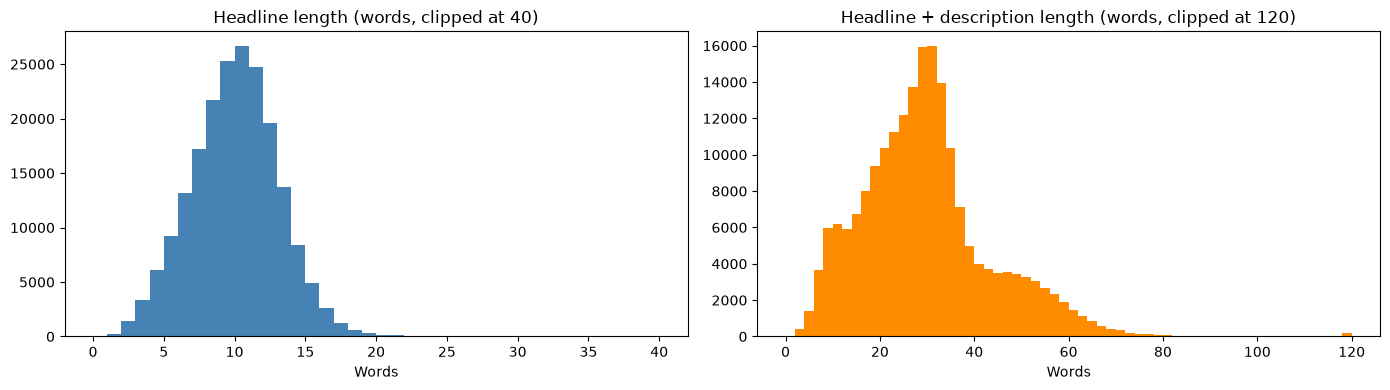

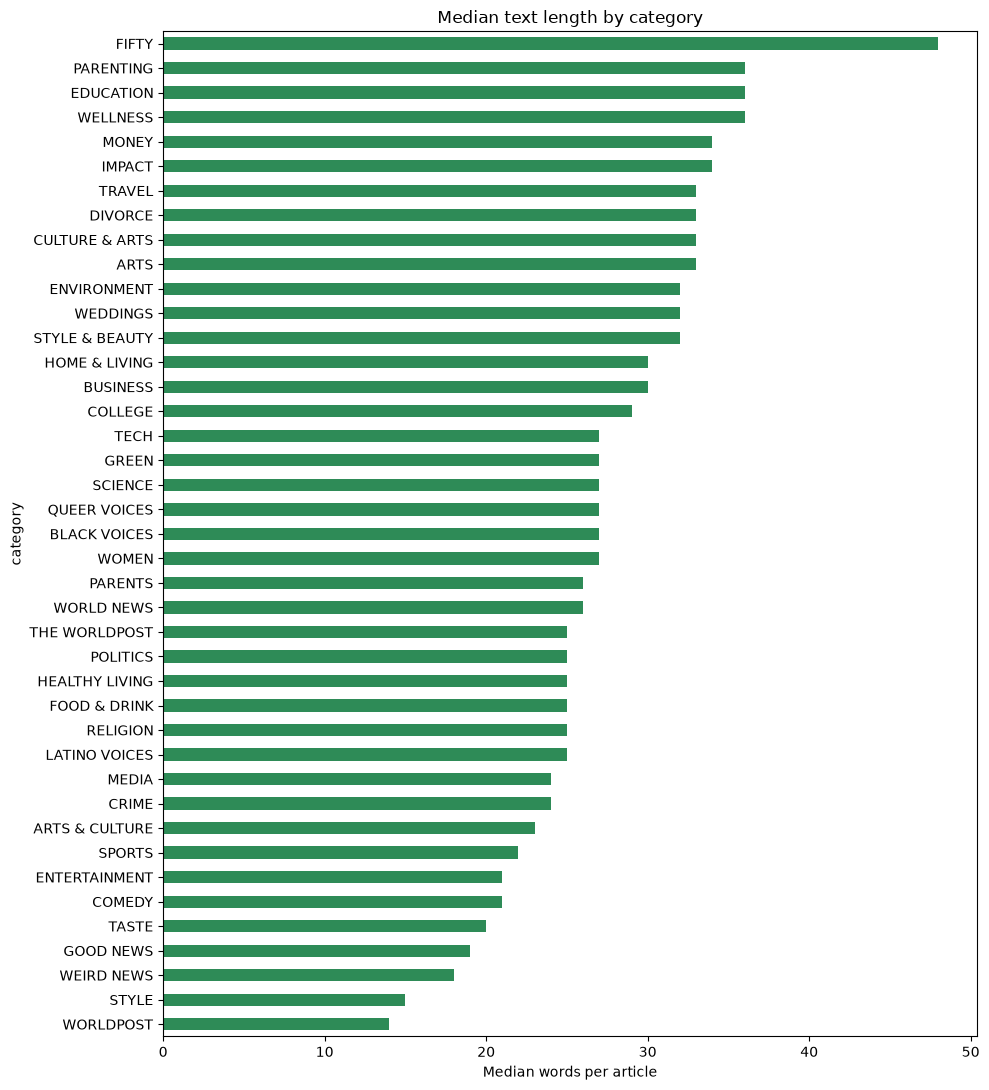

In [12]:
df_raw["n_words_headline"] = df_raw["headline"].str.split().str.len()
df_raw["n_words_desc"] = df_raw["short_description"].str.split().str.len()
df_raw["n_words_text"] = df_raw["n_words_headline"] + df_raw["n_words_desc"]
display(df_raw[["n_words_headline", "n_words_desc", "n_words_text"]]
        .describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

word_counts = Counter(w for t in df_raw["text"].str.lower() for w in re.findall(r"[a-z0-9']+", t) if w != "sep")
print("Vocabulary size (lowercased word types):", f"{len(word_counts):,}")
print("Words appearing only once:", f"{sum(1 for c in word_counts.values() if c == 1):,}")
print("Texts with fewer than 5 words:", int((df_raw["n_words_text"] < 5).sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df_raw["n_words_headline"].clip(upper=40), bins=40, color="steelblue")
axes[0].set_title("Headline length (words, clipped at 40)")
axes[0].set_xlabel("Words")
axes[1].hist(df_raw["n_words_text"].clip(upper=120), bins=60, color="darkorange")
axes[1].set_title("Headline + description length (words, clipped at 120)")
axes[1].set_xlabel("Words")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 11))
df_raw.groupby("category")["n_words_text"].median().sort_values().plot.barh(ax=ax, color="seagreen")
ax.set_xlabel("Median words per article")
ax.set_title("Median text length by category")
plt.tight_layout()
plt.show()

**P1.5 Label overlap:** Categories by year to spot renamed sections.

In [13]:
df_raw["year"] = pd.to_datetime(df_raw["date"]).dt.year

overlap_groups = [
    ["WORLDPOST", "THE WORLDPOST", "WORLD NEWS"],
    ["ARTS", "ARTS & CULTURE", "CULTURE & ARTS"],
    ["PARENTING", "PARENTS"],
    ["STYLE", "STYLE & BEAUTY"],
    ["WELLNESS", "HEALTHY LIVING"],
    ["GREEN", "ENVIRONMENT"],
    ["TASTE", "FOOD & DRINK"],
    ["COLLEGE", "EDUCATION"],
]
overlap_groups = [[c for c in g if c in class_counts.index] for g in overlap_groups]

for group in overlap_groups:
    print("=" * 100)
    print(" vs ".join(group))
    display(pd.crosstab(df_raw.loc[df_raw["category"].isin(group), "category"],
                        df_raw.loc[df_raw["category"].isin(group), "year"]))
    for cat in group:
        sample = df_raw[df_raw["category"] == cat].sample(2, random_state=random_seed)
        for h in sample["headline"]:
            print(f"  [{cat}] {h}")

WORLDPOST vs THE WORLDPOST vs WORLD NEWS


year,2014,2015,2016,2017,2018
category,,,,,
THE WORLDPOST,0,512,2071,1081,0
WORLD NEWS,0,0,0,1612,565
WORLDPOST,1204,1131,226,18,0


  [WORLDPOST] The Kenya Massacre: Why We Need One Global Democracy
  [WORLDPOST] Iraq's Final Hours
  [THE WORLDPOST] Refugees Living In Brazil Show Their Support For Host Country’s Olympic Soccer Team
  [THE WORLDPOST] Japan Puts Military On Alert For Possible North Korea Missile Launch
  [WORLD NEWS] Vatican Bank’s Ex-Chief Indicted For Embezzlement And Money Laundering
  [WORLD NEWS] North And South Korea To Form Unified Ice Hockey Team, March Together In Winter Olympics
ARTS vs ARTS & CULTURE vs CULTURE & ARTS


year,2012,2013,2014,2015,2016,2017,2018
category,,,,,,,
ARTS,0,0,801,618,87,3,0
ARTS & CULTURE,0,0,0,207,596,523,13
CULTURE & ARTS,343,558,129,0,0,0,0


  [ARTS] Demiurge
  [ARTS] Why You Need Painting to Say That Painting Is Dead
  [ARTS & CULTURE] St. Vincent's Sleek Ernie Ball Collaboration Is An 'Equal-Opportunity' Guitar
  [ARTS & CULTURE] Here’s What Happened When We Played Pokémon Go At MoMA
  [CULTURE & ARTS] Reunion,  South Coast Repertory, Costa Mesa
  [CULTURE & ARTS] Tackling Torture Video Contest Finalists Announced -- Jury and Audience Voting Begins
PARENTING vs PARENTS


year,2012,2013,2014,2015,2016,2017,2018
category,,,,,,,
PARENTING,3127,4200,1350,0,0,0,0
PARENTS,0,0,969,947,774,1229,36


... (7 outputs left out)

year,2012,2013,2014,2015,2016,2017,2018
category,,,,,,,
FOOD & DRINK,1823,3420,983,0,0,0,0
TASTE,0,0,521,625,409,532,9


  [TASTE] Chef Mario Batali Takes Leave After 4 Women Accuse Him Of Sexual Misconduct
  [TASTE] What Prince Ate: An Interview With Prince's Personal Chefs
  [FOOD & DRINK] Stepping Into Spring
  [FOOD & DRINK] This Restaurant Only Does Grilled Cheese, and It's Awesome [VIDEO]
COLLEGE vs EDUCATION


year,2014,2015,2016,2017,2018
category,,,,,
COLLEGE,380,524,182,57,1
EDUCATION,323,320,98,231,32


  [COLLEGE] Mizzou Chancellor Says He's Not Going To Rush To Fire Melissa Click
  [COLLEGE] Can Change At UVA Make Campuses A Safer Place?
  [EDUCATION] Vergara v. California Decision: Teacher Tenure Is Not the Problem
  [EDUCATION] Leveling the Playing Field for Our Kids


**P1.6 Top words:** Most frequent words per category.

In [14]:
def top_words(category, k=12):
    counts = Counter(
        w for t in df_raw.loc[df_raw["category"] == category, "text"].str.lower()
        for w in re.findall(r"[a-z']+", t)
        if w not in ENGLISH_STOP_WORDS and len(w) > 2 and w != "sep"
    )
    return [w for w, _ in counts.most_common(k)]

compare_cats = [c for c in ["POLITICS", "WORLD NEWS", "WELLNESS", "HEALTHY LIVING", "PARENTING", "PARENTS"] if c in class_counts.index]
display(pd.DataFrame({c: top_words(c) for c in compare_cats}))

,POLITICS,WORLD NEWS,WELLNESS,HEALTHY LIVING,PARENTING,PARENTS
0,trump,trump,life,life,kids,kids
1,donald,north,health,health,children,parents
2,president,korea,people,people,parents,mom
3,new,said,time,new,time,day
4,gop,people,new,time,child,children
5,trump's,president,study,it's,baby,baby
6,clinton,new,it's,just,year,time
7,said,says,day,make,day,just
8,says,attack,make,sleep,it's,like
9,house,killed,like,day,like,year


### Graded Questions (2 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Dataset Summary:**  
   Describe your chosen dataset  (as if explaining to your *clueless boss* what you are working on).
   - State which dataset you are going to use.   
   - What kind of data does it contain (images or text)?  
   - How many samples and classes are there?  
   - What is the task you’ll perform (classification into what categories)?
   - What is the potential business use for this dataset?

In [15]:
# Your answer here, NOT in the next cell

a1a = """
I am working with the HuffPost News Category dataset, a dataset of 200,853 news articles published on HuffPost between 2012 and 2018. 
Each article comes with a headline, a short description, an author, a link, a date, and the one field we care about: the category an editor filed it under. 
The raw data has 41 categories, which I reduced to 36 after merging sections that were renamed over the years. The task is text classification. 
Given a headline and its short description, can a model tell us which section the article belongs to? For example, "There Were 2 Mass Shootings In Texas Last Week, 
But Only 1 On TV" should land in CRIME. The business case is straightforward: a newsroom or news aggregator publishing hundreds of stories a day 
could use this to auto-tag articles, route them into the right feeds, power recommendations, and target ads by topic.
"""

In [16]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
I am working with the HuffPost News Category dataset, a dataset of 200,853 news articles published on HuffPost between 2012 and 2018. 
Each article comes with a headline, a short description, an author, a link, a date, and the one field we care about: the category an editor filed it under. 
The raw data has 41 categories, which I reduced to 36 after merging sections that were renamed over the years. The task is text classification. 
Given a headline and its short description, can a model tell us which section the article belongs to? For example, "There Were 2 Mass Shootings In Texas Last Week, 
But Only 1 On TV" should land in CRIME. The business case is straightforward: a newsroom or news aggregator publishing hundreds of stories a day 
could use this to auto-tag articles, route them into the right feeds, power recommendations, and target ads by topic.



B. **Initial Observations:**  
   What stood out to you from your EDA?  
   - Did you notice any imbalanced or ambiguous classes?  
   - Any patterns, anomalies, or potential sources of bias?  
   - For images: note any variation in lighting, composition, or color.  
   - For text: mention redundancy, topic overlap, or very short examples.

In [17]:
# Your answer here, NOT in the next cell

a1b = """
Three things stood out. First, the imbalance is severe. POLITICS alone holds 32,739 articles, 16.3% of the dataset, while EDUCATION has only 1,004. 
Second, and sneakier, some labels are not really different categories at all. The year crosstab shows PARENTING running from 2012 to 2014 and PARENTS 
taking over from 2014 to 2018, and the same handover happens for STYLE & BEAUTY into STYLE, WELLNESS into HEALTHY LIVING, and WORLDPOST into THE WORLDPOST. 
These are renamed sections, not new topics. Third, the text itself is thin: 19,712 articles have no description at all and 981 have fewer than five words. 
I also found 488 duplicate texts and 15 texts filed under two different categories. Finally, there is a temporal bias worth flagging. 
"Trump" is the top word in both POLITICS and WORLD NEWS, so the model may learn the 2016 to 2018 news cycle rather than the topic itself.
"""

In [18]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
Three things stood out. First, the imbalance is severe. POLITICS alone holds 32,739 articles, 16.3% of the dataset, while EDUCATION has only 1,004. 
Second, and sneakier, some labels are not really different categories at all. The year crosstab shows PARENTING running from 2012 to 2014 and PARENTS 
taking over from 2014 to 2018, and the same handover happens for STYLE & BEAUTY into STYLE, WELLNESS into HEALTHY LIVING, and WORLDPOST into THE WORLDPOST. 
These are renamed sections, not new topics. Third, the text itself is thin: 19,712 articles have no description at all and 981 have fewer than five words. 
I also found 488 duplicate texts and 15 texts filed under two different categories. Finally, there is a temporal bias worth flagging. 
"Trump" is the top word in both POLITICS and WORLD NEWS, so the model may learn the 2016 to 2018 news cycle rather than the topic itself.



C. **Challenges & Implications:**  
   Based on your inspection, what challenges might affect model performance or training (e.g., imbalance, ambiguous labels, variable quality)?  

In [19]:
# Your answer here, NOT in the next cell

a1c = """
The imbalance is the first trap. A lazy model that predicts POLITICS for everything gets 16.3% accuracy, 
and any model will be tempted to lean toward the big classes, so accuracy alone would hide how badly the small ones are doing. 
That pushes me toward macro-F1. The second challenge is label ambiguity. Renamed sections and overlapping ones, like WELLNESS and HEALTHY LIVING 
with a TF-IDF centroid similarity of 0.93, create errors no model can fix, because the labels reflect HuffPost's editorial desks rather than pure topics. 
That sets a ceiling below 100% from the start. Third, many texts are short and the vocabulary has a long tail: 107,427 distinct words, 
45,147 of which appear only once. Duplicates could leak across splits and flatter the validation scores. Finally, compute: my Codespace has 2 CPU cores, 
no GPU and 8.3 GB of RAM, which limits model size and sequence length.
"""

In [20]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

a1c = 
The imbalance is the first trap. A lazy model that predicts POLITICS for everything gets 16.3% accuracy, 
and any model will be tempted to lean toward the big classes, so accuracy alone would hide how badly the small ones are doing. 
That pushes me toward macro-F1. The second challenge is label ambiguity. Renamed sections and overlapping ones, like WELLNESS and HEALTHY LIVING 
with a TF-IDF centroid similarity of 0.93, create errors no model can fix, because the labels reflect HuffPost's editorial desks rather than pure topics. 
That sets a ceiling below 100% from the start. Third, many texts are short and the vocabulary has a long tail: 107,427 distinct words, 
45,147 of which appear only once. Duplicates could leak across splits and flatter the validation scores. Finally, compute: my Codespace has 2 CPU cores, 
no GPU and 8.3 GB of RAM, which limits model size and sequence length.



D. **Preparation Ideas:**  
   What data-cleaning or preprocessing steps might help address these issues?  
   (You will not implement these yet—just describe what you might do later.)

In [21]:
# Your answer here, NOT in the next cell

a1d = """
My plan is to clean first and model second. I would merge the labels that are clearly renamed versions of each other, 
drop the empty and very short texts, remove the texts with conflicting labels, and deduplicate before splitting so the same article can never sit in both train and test. 
For the input, I would combine headline and description with a [SEP] token, lowercase everything, strip punctuation, 
cap the vocabulary, and set the maximum sequence length near the 95th percentile so only a small share of texts get cut. 
Imbalance gets balanced class weights and a stratified split. What I would not do matters too. Oversampling repeats the same headlines and invites the model to memorize them. 
Stop-word removal and lemmatization with spaCy are slow on 2 cores, and a learned embedding can learn that "the" carries no topic signal. Problem 3 implements this plan.
"""

In [22]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1d = {a1d}")

a1d = 
My plan is to clean first and model second. I would merge the labels that are clearly renamed versions of each other, 
drop the empty and very short texts, remove the texts with conflicting labels, and deduplicate before splitting so the same article can never sit in both train and test. 
For the input, I would combine headline and description with a [SEP] token, lowercase everything, strip punctuation, 
cap the vocabulary, and set the maximum sequence length near the 95th percentile so only a small share of texts get cut. 
Imbalance gets balanced class weights and a stratified split. What I would not do matters too. Oversampling repeats the same headlines and invites the model to memorize them. 
Stop-word removal and lemmatization with spaCy are slow on 2 cores, and a learned embedding can learn that "the" carries no topic signal. Problem 3 implements this plan.



E. **Reflection:**  
   Why did you choose this dataset over the other one?  
   - What makes it more interesting, realistic, or relevant for you?  
   - What do you expect to learn from working with it?

In [23]:
# Your answer here, NOT in the next cell

a1e = """
I chose HuffPost over Food-101 for two reasons, one practical and one personal. The practical one is compute. 
Food-101 means 101,000 images to load and resize, and on a Codespace with 2 CPU cores and no GPU that is hours per experiment, while HuffPost trains a baseline in about four minutes. 
The personal reason is that this dataset is messier, and messy is more realistic. Food-101 is perfectly balanced at 1,000 images per class, which almost never happens in practice. 
HuffPost has imbalance, renamed labels and overlapping categories, which is exactly what support tickets or a company's document archive look like. 
I am also more drawn to NLP. From this project I expect to learn how to handle imbalance, how to choose a metric that does not flatter the model, 
and how far we can go from a bag of words baseline to sequence models and pretrained transformers like DistilBERT.
"""

In [24]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1e = {a1e}")

a1e = 
I chose HuffPost over Food-101 for two reasons, one practical and one personal. The practical one is compute. 
Food-101 means 101,000 images to load and resize, and on a Codespace with 2 CPU cores and no GPU that is hours per experiment, while HuffPost trains a baseline in about four minutes. 
The personal reason is that this dataset is messier, and messy is more realistic. Food-101 is perfectly balanced at 1,000 images per class, which almost never happens in practice. 
HuffPost has imbalance, renamed labels and overlapping categories, which is exactly what support tickets or a company's document archive look like. 
I am also more drawn to NLP. From this project I expect to learn how to handle imbalance, how to choose a metric that does not flatter the model, 
and how far we can go from a bag of words baseline to sequence models and pretrained transformers like DistilBERT.



## Problem 2 — Frame the Problem (15 pts)

#### Objective

Identify the **key challenges** in your chosen dataset and outline **practical solutions** you would try, plus how you’ll **evaluate** them later.

#### Steps to follow

1. **Diagnose likely challenges (from your EDA):**

   Examples:
   * **Class imbalance:**
     Report label counts and an imbalance ratio (max / median). List any minority classes.
   * **Length/size variance:**
     For text, show length percentiles (50/75/90/95) and estimate truncation rate at candidate `max_text_length`s (e.g., 256/300/512). For images, summarize native resolutions.
   * **Noise/duplicates/leakage:**
     Note empty or malformed items, near-duplicates, and how you would prevent cross-split leakage.
   * **Ambiguous/overlapping labels:**
     Give 2–3 example pairs you expect to be confusable and why.
   * **Compute constraints:**
     Briefly state limits (RAM/GPU/CPU) that might affect batch size, sequence length, or image size.

2. **Map each challenge to a concrete solution plan:**

   Examples:
   * **Imbalance →** `class_weight` or oversampling; report which one you’d try first and why.
   * **Length/size →** pick a target `max_text_length` (e.g., 95th percentile) with masking; for images, standardize resize/crop and basic augmentation.
   * **Noise/duplicates →** dedupe (hash/near-dup), drop empty/very short items, document any relabeling.
   * **Ambiguity →** consider merging labels (if justified), or add features (bigrams/char-ngrams; simple image augmentations).
   * **Overfitting risk →** early stopping on your primary metric, dropout/weight decay, freeze-then-finetune plan (for pretrained features).

3. **Explore appropriate evaluation metrics:**

   Examples:
   * **Primary metric:** pick one aligned to your data (e.g., **macro-F1** if imbalanced; accuracy if balanced).
   * **Secondary metric(s):** per-class precision/recall, confusion matrix.
   * **Protocol:** stratified Train/Val/Test (e.g., 70/15/15), fixed seed, leakage checks.

4. **Answer the graded questions below.**



**P2.1 Imbalance:** Class ratios and minority classes.

In [25]:
# Your code here, add as many cells as you like. Provide organization and structure by appropriate comments, labels, and variable names. Explain what
# you are doing in case you come back to this in a year. 

imbalance = pd.Series({
    "largest_class": class_counts.idxmax(),
    "largest_count": int(class_counts.max()),
    "median_count": float(class_counts.median()),
    "smallest_class": class_counts.idxmin(),
    "smallest_count": int(class_counts.min()),
    "max_over_median": round(class_counts.max() / class_counts.median(), 2),
    "max_over_min": round(class_counts.max() / class_counts.min(), 2),
})
display(imbalance.to_frame("value"))

minority = class_counts[class_counts < 0.5 * class_counts.median()]
print(f"Minority classes (< 50% of median, n={len(minority)}):")
display(minority.to_frame("count"))

,value
largest_class,POLITICS
largest_count,32739
median_count,3405.0
smallest_class,EDUCATION
smallest_count,1004
max_over_median,9.61
max_over_min,32.61


Minority classes (< 50% of median, n=9):


,count
category,
ARTS,1509
FIFTY,1401
GOOD NEWS,1398
ARTS & CULTURE,1339
ENVIRONMENT,1323
COLLEGE,1144
LATINO VOICES,1129
CULTURE & ARTS,1030
EDUCATION,1004


**P2.2 Truncation:** Length percentiles and cut-off rates.

In [26]:
df_raw["n_tokens"] = (df_raw["text"].str.lower()
                      .str.replace(r"[^\w\s]", " ", regex=True)
                      .str.split().str.len())

length_pcts = pd.Series({f"p{p}": np.percentile(df_raw["n_tokens"], p) for p in [50, 75, 90, 95, 99]})
display(length_pcts.to_frame("tokens"))

trunc_table = pd.DataFrame([
    {"max_text_length": L, "pct_truncated": round(100 * (df_raw["n_tokens"] > L).mean(), 2)}
    for L in [32, 48, 64, 96, 128, 256]
])
display(trunc_table)

,tokens
p50,30.0
p75,38.0
p90,51.0
p95,58.0
p99,69.0


,max_text_length,pct_truncated
0,32,41.03
1,48,12.26
2,64,2.06
3,96,0.12
4,128,0.08
5,256,0.00


**P2.3 Similar pairs:** Most similar categories by TF-IDF.

In [27]:
tfidf_eda = TfidfVectorizer(max_features=30000, stop_words="english", sublinear_tf=True)
X_eda = tfidf_eda.fit_transform(df_raw["text"].str.replace("[SEP]", " ", regex=False))
cats = class_counts.index.tolist()
codes = df_raw["category"].map({c: i for i, c in enumerate(cats)}).values
centroids = np.vstack([np.asarray(X_eda[codes == i].mean(axis=0)) for i in range(len(cats))])
sim = cosine_similarity(centroids)

pairs = [(cats[i], cats[j], sim[i, j]) for i in range(len(cats)) for j in range(i + 1, len(cats))]
pairs_df = pd.DataFrame(pairs, columns=["class_a", "class_b", "centroid_cosine"]).sort_values("centroid_cosine", ascending=False)
print("Most similar category pairs (TF-IDF centroid cosine similarity):")
display(pairs_df.head(15).reset_index(drop=True).round(3))

Most similar category pairs (TF-IDF centroid cosine similarity):


,class_a,class_b,centroid_cosine
0,PARENTING,PARENTS,0.940
1,WELLNESS,HEALTHY LIVING,0.930
2,FOOD & DRINK,TASTE,0.895
3,THE WORLDPOST,WORLD NEWS,0.847
4,ARTS,CULTURE & ARTS,0.775
5,THE WORLDPOST,WORLDPOST,0.766
6,GREEN,ENVIRONMENT,0.749
7,ARTS,ARTS & CULTURE,0.741
8,WORLDPOST,WORLD NEWS,0.712
9,STYLE & BEAUTY,STYLE,0.698


**P2.4 Compute:** Available CPU, GPU, and RAM.

In [28]:
print("CPU cores:", os.cpu_count())
print("GPUs:", tf.config.list_physical_devices("GPU"))
try:
    import psutil
    print(f"RAM total: {psutil.virtual_memory().total / 1e9:.1f} GB | available: {psutil.virtual_memory().available / 1e9:.1f} GB")
except ImportError:
    pass
print(f"Raw DataFrame memory: {df_raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")

CPU cores: 2
GPUs: []
RAM total: 8.3 GB | available: 5.2 GB
Raw DataFrame memory: 116.6 MB


E0000 00:00:1794762781.387972    2711 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



### Graded Questions (3 pts each)

Write **a coherent response of approximately 75–125 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits. Straightforward factual questions (such as identifying inputs and outputs) may be answered more briefly when fully addressed.

A. **State the prediction task**  
   - Describe what your model will predict (the *label*).  
   - *Examples:*  
     - “Given a photo of food, predict which of 101 categories it belongs to.”  
     - “Given a news headline + summary, predict its topical category.”  

In [29]:
# Your answer here, NOT in the next cell

a2a = """
Given a news article's headline and short description, the model predicts which one of 36 categories the article belongs to. 
This is a single label, multiclass text classification problem: every article gets exactly one category, and the model has to pick it from the text alone, 
with no access to the author, date or link. It is worth being precise about what the label actually is. 
It is not an objective topic, it is the editorial section HuffPost filed the story under at publication, between 2012 and 2018. 
That distinction explains up front why some confusion between neighboring sections, like WELLNESS and HEALTHY LIVING, is expected rather than a modeling failure.
"""

In [30]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
Given a news article's headline and short description, the model predicts which one of 36 categories the article belongs to. 
This is a single label, multiclass text classification problem: every article gets exactly one category, and the model has to pick it from the text alone, 
with no access to the author, date or link. It is worth being precise about what the label actually is. 
It is not an objective topic, it is the editorial section HuffPost filed the story under at publication, between 2012 and 2018. 
That distinction explains up front why some confusion between neighboring sections, like WELLNESS and HEALTHY LIVING, is expected rather than a modeling failure.



B. **Define inputs and outputs**  
   - *Inputs:* what information the model receives (e.g., pixel data, tokenized text).  
   - *Outputs:* the categorical label the model will predict.  

In [31]:
# Your answer here, NOT in the next cell

a2b = """
The input is a single string built as "headline [SEP] short description", lowercased and stripped of extra whitespace. 
A Keras TextVectorization layer, fit on the training split only, turns that string into a sequence of 58 integer token IDs from a 30,000 word vocabulary. 
Shorter texts are padded with 0 and unknown words map to 1, so each batch enters the model with shape (batch, 58) as int64. 
The output is a softmax probability vector over the 36 categories, shape (batch, 36), and the predicted label is simply the class with the highest probability. 
Labels are stored as integer IDs from 0 to 35, which is why I use sparse categorical cross-entropy. Padding is masked inside the model, so the zeros never dilute the average.
"""

In [32]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
The input is a single string built as "headline [SEP] short description", lowercased and stripped of extra whitespace. 
A Keras TextVectorization layer, fit on the training split only, turns that string into a sequence of 58 integer token IDs from a 30,000 word vocabulary. 
Shorter texts are padded with 0 and unknown words map to 1, so each batch enters the model with shape (batch, 58) as int64. 
The output is a softmax probability vector over the 36 categories, shape (batch, 36), and the predicted label is simply the class with the highest probability. 
Labels are stored as integer IDs from 0 to 35, which is why I use sparse categorical cross-entropy. Padding is masked inside the model, so the zeros never dilute the average.



C. **Identify possible challenges**  
   - Imbalanced classes, noisy data, ambiguous labels, overlapping features, or missing data  
   - *Images:* variation in lighting, color, composition, or size.  
   - *Text:* class imbalance, duplicate stories, short or ambiguous headlines.  

In [33]:
# Your answer here, NOT in the next cell

a2c = """
The biggest challenge is imbalance: the largest class is 9.6 times the median and 32.6 times the smallest, and 9 classes fall below half the median. 
The median text is 30 tokens but the 95th percentile is 58: at 32 tokens, 41% of texts would be truncated, 12.3% at 48, and only 2.1% at 64. 
On noise, I found 5 empty texts, 488 duplicates and 15 conflicting labels. The confusable pairs stand out in the TF-IDF table: PARENTING and PARENTS at 0.94, 
WELLNESS and HEALTHY LIVING at 0.93, and FOOD & DRINK and TASTE at 0.90. Finally, with 2 CPU cores and no GPU, I need a model that trains in minutes, not hours.
"""

In [34]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
The biggest challenge is imbalance: the largest class is 9.6 times the median and 32.6 times the smallest, and 9 classes fall below half the median. 
The median text is 30 tokens but the 95th percentile is 58: at 32 tokens, 41% of texts would be truncated, 12.3% at 48, and only 2.1% at 64. 
On noise, I found 5 empty texts, 488 duplicates and 15 conflicting labels. The confusable pairs stand out in the TF-IDF table: PARENTING and PARENTS at 0.94, 
WELLNESS and HEALTHY LIVING at 0.93, and FOOD & DRINK and TASTE at 0.90. Finally, with 2 CPU cores and no GPU, I need a model that trains in minutes, not hours.



D. **Propose how you will prepare or improve the data to address the challenges**  
   - *Images:* resizing, normalization, data augmentation (flips, rotations, brightness, color jitter).  
   - *Text:* tokenization, stop-word removal, TF-IDF, class balancing, embeddings (choose an embedding approach and specify its vector size). 

In [35]:
# Your answer here, NOT in the next cell

a2d = """
Imbalance gets balanced class weights rather than oversampling, which just repeats headlines. Length gets MAX_LEN = 58, the 95th percentile, 
truncating only 4.7% of texts, with padding masked. Noise gets dropped: empty texts, texts under 3 words, conflicting labels, and duplicates by text and link. 
For ambiguity, I merge the 5 labels whose names are clearly variants of each other, going from 41 to 36 classes. 
The embedding is learned, a 64 dimensional vector for each of the 30,000 vocabulary words. Overfitting gets 0.3 dropout and early stopping (patience 5). 
One honest caveat: the year crosstab shows WELLNESS, FOOD & DRINK and ENVIRONMENT were also renamed in 2014. They are first in line for the final project.
"""

In [36]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
Imbalance gets balanced class weights rather than oversampling, which just repeats headlines. Length gets MAX_LEN = 58, the 95th percentile, 
truncating only 4.7% of texts, with padding masked. Noise gets dropped: empty texts, texts under 3 words, conflicting labels, and duplicates by text and link. 
For ambiguity, I merge the 5 labels whose names are clearly variants of each other, going from 41 to 36 classes. 
The embedding is learned, a 64 dimensional vector for each of the 30,000 vocabulary words. Overfitting gets 0.3 dropout and early stopping (patience 5). 
One honest caveat: the year crosstab shows WELLNESS, FOOD & DRINK and ENVIRONMENT were also renamed in 2014. They are first in line for the final project.



E. **Specify success metrics**  
   - Identify the metrics you plan to use to evaluate model performance—typically **accuracy** and/or **F1-score**, which are standard for classification tasks.  
   - Briefly explain **why** these metrics are appropriate for your dataset and goal. For instance, accuracy may suffice for well-balanced datasets, while F1-score better reflects performance when some classes are under-represented.
   - If your dataset is **imbalanced**, consider computing **per-class metrics** (e.g., precision, recall, or F1 for each label) or **macro-averaged** scores, which give equal weight to each class regardless of its size—ensuring that minority classes are evaluated fairly.
In some cases, weighted averages (which weight classes by their frequency) or **confusion matrices** can also provide useful insight.
> You haven't run any models yet, and we haven’t studied every possible metric, but you’re encouraged to ask your favorite generative AI tool which evaluation metrics might best fit your dataset!
   - Clearly state how you will interpret success—for example, “Our goal is to achieve at least 80% overall accuracy without large per-class disparities.”

In [37]:
# Your answer here, NOT in the next cell

a2e = """
My primary metric is macro-F1. With POLITICS holding 16.3% of the data and EDUCATION 0.5%, accuracy would reward a model that ignores the small classes, 
while macro-F1 gives every class an equal vote. I still report accuracy, since the course benchmark is validation accuracy at the epoch of minimum validation loss, 
plus weighted F1, per-class precision, recall and F1, and a confusion matrix. The protocol is a stratified 80/10/10 split with seed 42, leakage checks, 
and a test set nobody touches until the final project. I also track top-3 accuracy, because an editor suggestion tool only needs the right section in its top three. 
Success means the final model beats the baseline's validation macro-F1 by at least 10 points, with no class below 0.30 F1.
"""

In [38]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2e = {a2e}")

a2e = 
My primary metric is macro-F1. With POLITICS holding 16.3% of the data and EDUCATION 0.5%, accuracy would reward a model that ignores the small classes, 
while macro-F1 gives every class an equal vote. I still report accuracy, since the course benchmark is validation accuracy at the epoch of minimum validation loss, 
plus weighted F1, per-class precision, recall and F1, and a confusion matrix. The protocol is a stratified 80/10/10 split with seed 42, leakage checks, 
and a test set nobody touches until the final project. I also track top-3 accuracy, because an editor suggestion tool only needs the right section in its top three. 
Success means the final model beats the baseline's validation macro-F1 by at least 10 points, with no class below 0.30 F1.



## Problem 3 — Data Preparation and Splits (30 pts)

### Goals

Implement the **data preparation and preprocessing steps** that you proposed in **Problems 1–2**. You’ll clean, normalize, and split your data so that it’s ready for modeling and reproducible modeling.

### Steps to Follow

1. **Load your chosen dataset**

   * Use `datasets.load_dataset()` from **Hugging Face** to load **Food-101** or **HuffPost**.
   * Display basic information (e.g., number of samples, feature names, example entries).

2. **Apply cleaning and normalization**

   * **Images:**

     * Ensure all images are in RGB format.
     * Resize or crop to a consistent shape (e.g., `224 × 224`).
     * Drop or fix any corrupted files.
   * **Text:**

     * Concatenate headline + summary (for HuffPost).
     * Strip whitespace, convert to lowercase if appropriate, and remove empty samples.
     * Optionally remove duplicates or extremely short entries.

3. **Standardize or tokenize the inputs**

   * **Images:**

     * Normalize pixel values (e.g., divide by 255.0).
     * Define a minimal augmentation pipeline (e.g., random flip, crop, or rotation).
   * **Text:**

     * Create a tokenizer or `TextVectorization` layer.
     * Set a target `max_length` based on your analysis from your earlier exploration in this notebook (e.g., 95th percentile).
     * Apply padding/truncation and build tensors for input + labels.

4. **Handle dataset-specific challenges**

   * If you identified **class imbalance**, compute label counts and, if needed, create a dictionary of `class_weights`.
   * If you noted **length or size variance**, verify that your truncation or resizing works as intended.
   * If you planned **noise filtering**, include the cleaning step and briefly explain your criteria (e.g., remove items with missing text or unreadable images).

5. **Create reproducible splits**

   * Split your cleaned dataset into **train**, **validation**, and **test** subsets (e.g., 80 / 10 / 10).
   * Use a fixed random seed for reproducibility (`random_seed = 42`).
   * Use **stratified splits**  (e.g., with `train_test_split` and `stratify = labels`).
   * Display the size of each subset.

6. **Document your pipeline**

   * Summarize your preprocessing steps clearly in Markdown or code comments.
   * Save or display a few representative examples after preprocessing to confirm the transformations are correct.




**Test-set policy:** Create and verify the test split, but **do not train on or evaluate models against it** in this milestone. Fit preprocessing parameters (e.g. vocabulary, scaling) on training data only; apply the fitted transformations to validation and test examples. Apply random augmentation to training data only.


**P3.1 Cleaning:** Merge labels, remove bad and duplicate rows.

In [39]:
# Your code here; add as many cells as you need but make it clear what the structure is. 
MERGE_LABELS = True
MIN_WORDS = 3
label_merges = {
    "THE WORLDPOST": "WORLDPOST",
    "ARTS": "ARTS & CULTURE",
    "CULTURE & ARTS": "ARTS & CULTURE",
    "PARENTS": "PARENTING",
    "STYLE": "STYLE & BEAUTY",
}

df = df_raw[["category", "headline", "short_description", "link", "date"]].copy()
df["text"] = (df["headline"] + " [SEP] " + df["short_description"]).str.strip()
df["text_clean"] = df["text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
df["n_words"] = df["headline"].str.split().str.len() + df["short_description"].str.split().str.len()

cleaning_log = {"raw_rows": len(df)}
if MERGE_LABELS:
    df["category"] = df["category"].replace(label_merges)
cleaning_log["classes_after_merge"] = df["category"].nunique()

df = df[~((df["headline"] == "") & (df["short_description"] == ""))]
cleaning_log["after_drop_empty"] = len(df)

df = df[df["n_words"] >= MIN_WORDS]
cleaning_log[f"after_drop_under_{MIN_WORDS}_words"] = len(df)

conflicting = df.groupby("text_clean")["category"].transform("nunique") > 1
df = df[~conflicting]
cleaning_log["after_drop_conflicting_labels"] = len(df)

df = df.drop_duplicates("text_clean").drop_duplicates("link")
cleaning_log["after_dedupe_text_and_link"] = len(df)
df = df.reset_index(drop=True)

display(pd.Series(cleaning_log).to_frame("value"))

,value
raw_rows,200853
classes_after_merge,36
after_drop_empty,200848
after_drop_under_3_words,200646
after_drop_conflicting_labels,200622
after_dedupe_text_and_link,200122


**P3.2 Split:** Stratified 80/10/10 split and leakage check.

In [40]:
class_names = sorted(df["category"].unique())
label2id = {c: i for i, c in enumerate(class_names)}
df["label"] = df["category"].map(label2id).astype("int32")
NUM_CLASSES = len(class_names)
print("Number of classes:", NUM_CLASSES)

train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=random_seed)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=random_seed)
train_df, val_df, test_df = (d.reset_index(drop=True) for d in (train_df, val_df, test_df))

split_sizes = pd.DataFrame({
    "rows": [len(train_df), len(val_df), len(test_df)],
    "pct": [round(100 * len(d) / len(df), 2) for d in (train_df, val_df, test_df)],
}, index=["train", "val", "test"])
display(split_sizes)

dist = pd.DataFrame({
    "train": train_df["category"].value_counts(normalize=True),
    "val": val_df["category"].value_counts(normalize=True),
    "test": test_df["category"].value_counts(normalize=True),
}).sort_values("train", ascending=False)
print("Max absolute difference in class proportion vs train:",
      round(float((dist[["val", "test"]].sub(dist["train"], axis=0)).abs().max().max()), 5))
display((100 * dist).round(2))

leak = pd.Series({
    "train∩val texts": len(set(train_df["text_clean"]) & set(val_df["text_clean"])),
    "train∩test texts": len(set(train_df["text_clean"]) & set(test_df["text_clean"])),
    "val∩test texts": len(set(val_df["text_clean"]) & set(test_df["text_clean"])),
    "train∩val links": len(set(train_df["link"]) & set(val_df["link"])),
    "train∩test links": len(set(train_df["link"]) & set(test_df["link"])),
    "val∩test links": len(set(val_df["link"]) & set(test_df["link"])),
})
display(leak.to_frame("overlap_count"))
assert leak.sum() == 0

Number of classes: 36


,rows,pct
train,160097,80.0
val,20012,10.0
test,20013,10.0


Max absolute difference in class proportion vs train: 4e-05


,train,val,test
category,,,
POLITICS,16.33,16.33,16.33
WELLNESS,8.91,8.90,8.90
ENTERTAINMENT,8.02,8.02,8.02
PARENTING,6.27,6.27,6.27
STYLE & BEAUTY,5.87,5.87,5.87
TRAVEL,4.94,4.94,4.94
HEALTHY LIVING,3.33,3.33,3.33
QUEER VOICES,3.15,3.15,3.15
WORLDPOST,3.11,3.11,3.11


,overlap_count
train∩val texts,0
train∩test texts,0
val∩test texts,0
train∩val links,0
train∩test links,0
val∩test links,0


**P3.3 Save splits:** Save splits to CSV for reuse.

In [41]:
os.makedirs("huffpost_splits", exist_ok=True)
keep_cols = ["text", "text_clean", "category", "label", "link"]
train_df[keep_cols].to_csv("huffpost_splits/train.csv", index=False)
val_df[keep_cols].to_csv("huffpost_splits/val.csv", index=False)
test_df[keep_cols].to_csv("huffpost_splits/test.csv", index=False)
with open("huffpost_splits/class_names.json", "w") as f:
    json.dump(class_names, f)
print(os.listdir("huffpost_splits"))

['test.csv', 'class_names.json', 'vocab.txt', 'val.csv', 'train.csv']


**P3.4 Vectorization:** Build vocabulary from training data only.

In [42]:
def count_tokens(series):
    return series.str.replace(r"[^\w\s]", " ", regex=True).str.split().str.len()

train_token_lengths = count_tokens(train_df["text_clean"])
VOCAB_SIZE = 30000
MAX_LEN = int(np.ceil(np.percentile(train_token_lengths, 95)))
print("MAX_LEN (95th percentile of training token counts):", MAX_LEN)

vectorizer = layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    output_mode="int",
    output_sequence_length=MAX_LEN,
    standardize="lower_and_strip_punctuation",
)
vectorizer.adapt(tf.data.Dataset.from_tensor_slices(train_df["text_clean"].values).batch(2048))
vocab_list = [str(t) for t in vectorizer.get_vocabulary()]
print("Vocabulary size used:", len(vocab_list))
print("First 20 tokens:", vocab_list[:20])

with open("huffpost_splits/vocab.txt", "w") as f:
    f.write("\n".join(vocab_list))

val_ids_sample = vectorizer(val_df["text_clean"].values[:5000]).numpy()
trunc_check = pd.Series({
    "train_pct_truncated": round(100 * (train_token_lengths > MAX_LEN).mean(), 2),
    "val_pct_truncated": round(100 * (count_tokens(val_df["text_clean"]) > MAX_LEN).mean(), 2),
    "val_pct_oov_tokens": round(100 * (val_ids_sample == 1).sum() / max((val_ids_sample > 0).sum(), 1), 2),
})
display(trunc_check.to_frame("value"))

MAX_LEN (95th percentile of training token counts): 58
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step
Vocabulary size used: 30000
First 20 tokens: ['', '[UNK]', 'the', 'sep', 'to', 'a', 'of', 'and', 'in', 'is', 'for', 'that', 'on', 'you', 'with', 'i', 'it', 'are', 'this', 'be']


,value
train_pct_truncated,4.71
val_pct_truncated,4.71
val_pct_oov_tokens,2.89


**P3.5 Class weights:** Balanced weights from training counts.

In [43]:
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].values)
class_weights = {i: float(w) for i, w in enumerate(cw)}
cw_table = pd.DataFrame({
    "class": class_names,
    "train_count": train_df["label"].value_counts().sort_index().values,
    "class_weight": np.round(cw, 3),
}).sort_values("train_count", ascending=False)
display(cw_table)

,class,train_count,class_weight
21,POLITICS,26149,0.170
32,WELLNESS,14257,0.312
8,ENTERTAINMENT,12838,0.346
20,PARENTING,10035,0.443
26,STYLE & BEAUTY,9400,0.473
29,TRAVEL,7901,0.563
14,HEALTHY LIVING,5335,0.834
22,QUEER VOICES,5045,0.881
35,WORLDPOST,4985,0.892
11,FOOD & DRINK,4980,0.893


**P3.6 Pipelines:** Batched datasets and shape checks

In [44]:
BATCH_SIZE = 128

def make_ds(frame, shuffle):
    ds = tf.data.Dataset.from_tensor_slices((frame["text_clean"].values, frame["label"].values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=random_seed, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (vectorizer(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds = make_ds(val_df, shuffle=False)
test_ds = make_ds(test_df, shuffle=False)

for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
    xb, yb = next(iter(ds))
    print(f"{name:5s} batch -> X {xb.shape} {xb.dtype} | y {yb.shape} {yb.dtype}")

for i in range(3):
    row = train_df.iloc[i]
    ids = vectorizer([row["text_clean"]]).numpy()[0]
    print("-" * 100)
    print("label   :", row["category"], f"(id={row['label']})")
    print("raw     :", row["text"])
    print("ids     :", ids[:25], "...")
    print("decoded :", " ".join(vocab_list[t] for t in ids if t > 0))

train batch -> X (128, 58) <dtype: 'int64'> | y (128,) <dtype: 'int32'>
val   batch -> X (128, 58) <dtype: 'int64'> | y (128,) <dtype: 'int32'>
test  batch -> X (128, 58) <dtype: 'int64'> | y (128,) <dtype: 'int32'>
----------------------------------------------------------------------------------------------------
label   : PARENTING (id=20)
raw     : A Dream Of Nerds [SEP] Just after Hurricane Sandy hit, the kid's class held a read-a-thon, the first-grade equivalent of a healthier lemonade stand
ids     : [    5   755     6 11139     3    57    63  1407  1780   512     2   115
   899  1225     5     1     2     1  6454     6     5  1884  6594   674
     0] ...
decoded : a dream of nerds sep just after hurricane sandy hit the kids class held a [UNK] the [UNK] equivalent of a healthier lemonade stand
----------------------------------------------------------------------------------------------------
label   : WELLNESS (id=32)
raw     : I'm Not Trying to Be Well-Adjusted [SEP] The other

### Grading for Problem 3 (30 pts)

- **Implementation (18 pts):** correct data loading and cleaning; appropriate preprocessing; reproducible, separate train/validation/test splits with leakage prevention; and checks/outputs demonstrating that the prepared data are suitable for modeling.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual implementation and cite your notebook results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Data Loading and Cleaning:**
   Describe how you loaded your dataset and the key cleaning steps you implemented (e.g., handling missing data, normalizing formats, or removing duplicates).



In [45]:
# Your answer here, NOT in the next cell

a3a = """
I loaded the dataset with Hugging Face's load_dataset from the JSON mirror, which gave 200,853 rows and six fields, then converted it to pandas. 
Nulls were filled with empty strings, whitespace was stripped, and headline and description were joined with a [SEP] token. The cleaning log tells the rest. 
Merging the 5 renamed labels took us from 41 to 36 classes. Dropping 5 empty texts left 200,848, removing 202 texts under three words left 200,646, 
removing 24 rows with conflicting labels left 200,622, and deduplicating on text and link removed another 500, for a final 200,122. Only 731 rows, 0.36% of the data, 
were removed. Two choices are worth defending. Conflicting rows were dropped rather than majority voted, because there is no ground truth to vote with. 
And deduplication happened before the split, on purpose, so the same article can never appear in both training and test.
"""

In [46]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
I loaded the dataset with Hugging Face's load_dataset from the JSON mirror, which gave 200,853 rows and six fields, then converted it to pandas. 
Nulls were filled with empty strings, whitespace was stripped, and headline and description were joined with a [SEP] token. The cleaning log tells the rest. 
Merging the 5 renamed labels took us from 41 to 36 classes. Dropping 5 empty texts left 200,848, removing 202 texts under three words left 200,646, 
removing 24 rows with conflicting labels left 200,622, and deduplicating on text and link removed another 500, for a final 200,122. Only 731 rows, 0.36% of the data, 
were removed. Two choices are worth defending. Conflicting rows were dropped rather than majority voted, because there is no ground truth to vote with. 
And deduplication happened before the split, on purpose, so the same article can never appear in both training and test.



B. **Preprocessing and Standardization:**
   Summarize your preprocessing pipeline. Include any normalization, tokenization, resizing, or augmentation steps, and explain why each was necessary for your dataset.
  

In [47]:
# Your answer here, NOT in the next cell

a3b = """
The preprocessing stays simple on purpose. Text is lowercased and repeated whitespace collapsed, then a Keras TextVectorization layer strips punctuation and maps words to integer IDs. 
The vocabulary is capped at 30,000 of the 107,427 distinct words, which still leaves only a 2.89% unknown word rate on validation. 
MAX_LEN is 58, the 95th percentile of training lengths, with shorter texts padded and longer ones truncated. Critically, the vectorizer was adapted on the training split only. 
I did not remove stop words, lemmatize or augment, since a learned embedding handles common words itself and text augmentation risks changing the meaning. 
Batches of 128 flow through a tf.data pipeline that shuffles training only, and the shape check confirmed (128, 58) int64. 
Decoding a few examples revealed two side effects: "well-adjusted" became "welladjusted", and [SEP] became the token "sep", second only to "the", 
which conveniently marks where the headline ends.
"""

In [48]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
The preprocessing stays simple on purpose. Text is lowercased and repeated whitespace collapsed, then a Keras TextVectorization layer strips punctuation and maps words to integer IDs. 
The vocabulary is capped at 30,000 of the 107,427 distinct words, which still leaves only a 2.89% unknown word rate on validation. 
MAX_LEN is 58, the 95th percentile of training lengths, with shorter texts padded and longer ones truncated. Critically, the vectorizer was adapted on the training split only. 
I did not remove stop words, lemmatize or augment, since a learned embedding handles common words itself and text augmentation risks changing the meaning. 
Batches of 128 flow through a tf.data pipeline that shuffles training only, and the shape check confirmed (128, 58) int64. 
Decoding a few examples revealed two side effects: "well-adjusted" became "welladjusted", and [SEP] became the token "sep", second only to "the", 
which conveniently marks where the headline ends.



C. **Train/Validation/Test Splits:**
   Explain how you divided your data into subsets, including the split ratios, random seed, and any stratification or leakage checks you used to verify correctness.


In [49]:
# Your answer here, NOT in the next cell

a3c = """
The split is done in two stages with scikit-learn's train_test_split, stratified by label with random seed 42. 
The first stage holds out 20%, and the second cuts that holdout in half, giving 160,097 training, 20,012 validation and 20,013 test articles, an 80/10/10. 
Stratification worked: no class proportion differs from training by more than 4e-05. For leakage, I checked every pair of splits for shared texts and shared 
links and found zero overlap, enforced with an assert so the notebook fails if that ever changes. The vocabulary, MAX_LEN and class weights were all fit on training only, 
and the splits are saved to CSV so the final project reuses the exact same partition. One caveat remains. The raw data had 1,504 duplicate headlines, and some survive 
with different descriptions, so near duplicates can still cross splits. The split is also random rather than chronological, a gentler test than next year's news.
"""

In [50]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3c = {a3c}")

a3c = 
The split is done in two stages with scikit-learn's train_test_split, stratified by label with random seed 42. 
The first stage holds out 20%, and the second cuts that holdout in half, giving 160,097 training, 20,012 validation and 20,013 test articles, an 80/10/10. 
Stratification worked: no class proportion differs from training by more than 4e-05. For leakage, I checked every pair of splits for shared texts and shared 
links and found zero overlap, enforced with an assert so the notebook fails if that ever changes. The vocabulary, MAX_LEN and class weights were all fit on training only, 
and the splits are saved to CSV so the final project reuses the exact same partition. One caveat remains. The raw data had 1,504 duplicate headlines, and some survive 
with different descriptions, so near duplicates can still cross splits. The split is also random rather than chronological, a gentler test than next year's news.



D. **Class Distribution and Balance:**
   Report your label counts and describe any class imbalances you observed. If applicable, explain how you addressed them (e.g., weighting, oversampling, or data augmentation).


In [51]:
# Your answer here, NOT in the next cell

a3d = """
The label counts are heavily skewed. POLITICS leads with 32,739 articles, 16.3% of the data, followed by WELLNESS at 17,827 and ENTERTAINMENT at 16,058, 
while EDUCATION sits at the bottom with 1,004. That is a 9.6 ratio of largest to median and 32.6 of largest to smallest. Merging renamed labels helped a little, 
lifting PARENTING to 6.27% and STYLE & BEAUTY to 5.87%, but training counts still range from 26,149 down to 803. I addressed this three ways: balanced class weights, 
from 0.170 for POLITICS up to 5.538 for EDUCATION, a stratified split, and macro-F1 as the primary metric. The baseline shows the weights did their job. 
Small classes now have recall above precision, EDUCATION at 0.505 versus 0.262, while POLITICS flips the other way at 0.867 precision and 0.596 recall. 
The model was pushed toward the small classes, a deliberate trade-off rather than a bug.
"""

In [52]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3d = {a3d}")

a3d = 
The label counts are heavily skewed. POLITICS leads with 32,739 articles, 16.3% of the data, followed by WELLNESS at 17,827 and ENTERTAINMENT at 16,058, 
while EDUCATION sits at the bottom with 1,004. That is a 9.6 ratio of largest to median and 32.6 of largest to smallest. Merging renamed labels helped a little, 
lifting PARENTING to 6.27% and STYLE & BEAUTY to 5.87%, but training counts still range from 26,149 down to 803. I addressed this three ways: balanced class weights, 
from 0.170 for POLITICS up to 5.538 for EDUCATION, a stratified split, and macro-F1 as the primary metric. The baseline shows the weights did their job. 
Small classes now have recall above precision, EDUCATION at 0.505 versus 0.262, while POLITICS flips the other way at 0.867 precision and 0.596 recall. 
The model was pushed toward the small classes, a deliberate trade-off rather than a bug.



## Problem 4 — Baseline Model (30 pts)

### Goal

Build and train a **simple, fully functional baseline model** to establish a reference level of performance for your dataset.
This baseline will help you evaluate whether later architectures and fine-tuning steps actually improve results.


### Steps to Follow

1. **Construct a baseline model**

   * **Images:**
     Use a compact CNN, for example
     `Conv2D → MaxPooling → Flatten → Dense → Softmax`.
   * **Text:**
     Use a small embedding-based classifier such as
     `Embedding → GlobalAveragePooling → Dense → Softmax`.
   * Keep the model small enough to train in minutes on Colab.

2. **Compile the model**

   * Optimizer: `Adam` or `AdamW`.
   * Loss: Use `categorical_crossentropy` for one-hot-encoded labels or `sparse_categorical_crossentropy` for integer class labels.
   * Metrics: at least `accuracy`; add `F1` if appropriate.

3. **Train and validate**

   * Use **early stopping** on validation loss with a patience of approximately 5 epochs.
   * Record number of epochs trained and total runtime.

4. **Visualize results**

   * Plot **training vs. validation accuracy and loss**.
   * Carefully observe: does the model underfit, overfit, or generalize reasonably?

5. **Report baseline performance**

   * The most important metric is the **validation accuracy at the epoch of minimum validation loss**; this serves as your **benchmark** for all later experiments in the final project.
   * **Do not evaluate on the test set yet.** Report validation performance only. Preserve the test split for final evaluation.

**P4.1 Baseline model:** Define model and macro-F1 callback.

In [53]:
# Your code here; add as many cells as you need but make it clear what the structure is. 
EMBED_DIM = 64
DROPOUT = 0.3
LEARNING_RATE = 1e-3
MAX_EPOCHS = 30
PATIENCE = 5

def build_baseline():
    inp = Input(shape=(MAX_LEN,), dtype="int64", name="token_ids")
    x = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True, name="embedding")(inp)
    x = layers.GlobalAveragePooling1D(name="avg_pool")(x)
    x = Dropout(DROPOUT, name="dropout")(x)
    out = Dense(NUM_CLASSES, activation="softmax", name="softmax")(x)
    return models.Model(inp, out, name="baseline_embedding_gap")

class ValMacroF1(Callback):
    def __init__(self, ds, y_true):
        super().__init__()
        self.ds = ds
        self.y_true = y_true
        self.scores = []
    def on_epoch_end(self, epoch, logs=None):
        y_pred = np.argmax(self.model.predict(self.ds, verbose=0), axis=1)
        score = f1_score(self.y_true, y_pred, average="macro")
        self.scores.append(score)
        if logs is not None:
            logs["val_macro_f1"] = score
        print(f"epoch {epoch + 1}: val_macro_f1 = {score:.4f}")

tf.keras.utils.set_random_seed(random_seed)
baseline = build_baseline()
baseline.compile(optimizer=Adam(learning_rate=LEARNING_RATE),
                 loss="sparse_categorical_crossentropy",
                 metrics=["accuracy"])
baseline.summary()

Model: "baseline_embedding_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ token_ids (InputLayer)          │ (None, 58)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 58, 64)         │     1,920,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ avg_pool                        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ softmax (Dense)                 │ (None, 36)             │         2,340 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,922,340 (7.33 MB)

 Trainable params: 1,922,340 (7.33 MB)

 Non-trainable params: 0 (0.00 B)

**P4.2 Training:** Train with early stopping.

In [54]:
f1_cb = ValMacroF1(val_ds, val_df["label"].values)
early_stop = EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1)

start_time = time.time()
history = baseline.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    class_weight=class_weights,
    callbacks=[f1_cb, early_stop],
    verbose=2,
)
train_seconds = time.time() - start_time
print("Training time:", format_hms(train_seconds))

Epoch 1/30


/usr/local/python/3.14.2/lib/python3.14/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


epoch 1: val_macro_f1 = 0.3944
1251/1251 - 16s - 12ms/step - accuracy: 0.4164 - loss: 3.0595 - val_accuracy: 0.5131 - val_loss: 2.2964 - val_macro_f1: 0.3944
Epoch 2/30
epoch 2: val_macro_f1 = 0.4613
1251/1251 - 15s - 12ms/step - accuracy: 0.5428 - loss: 2.1082 - val_accuracy: 0.5473 - val_loss: 1.8552 - val_macro_f1: 0.4613
Epoch 3/30
epoch 3: val_macro_f1 = 0.4880
1251/1251 - 20s - 16ms/step - accuracy: 0.5871 - loss: 1.6893 - val_accuracy: 0.5693 - val_loss: 1.6710 - val_macro_f1: 0.4880
Epoch 4/30
epoch 4: val_macro_f1 = 0.4964
1251/1251 - 21s - 17ms/step - accuracy: 0.6176 - loss: 1.4570 - val_accuracy: 0.5749 - val_loss: 1.5893 - val_macro_f1: 0.4964
Epoch 5/30
epoch 5: val_macro_f1 = 0.5093
1251/1251 - 14s - 11ms/step - accuracy: 0.6402 - loss: 1.2936 - val_accuracy: 0.5857 - val_loss: 1.5329 - val_macro_f1: 0.5093
Epoch 6/30
epoch 6: val_macro_f1 = 0.5140
1251/1251 - 15s - 12ms/step - accuracy: 0.6617 - loss: 1.1637 - val_accuracy: 0.5886 - val_loss: 1.5016 - val_macro_f1: 0.51

**P4.3 Learning curves:** Loss, accuracy, and macro-F1 by epoch.

,accuracy,loss,val_accuracy,val_loss,val_macro_f1
epoch,,,,,
1,0.4164,3.0595,0.5131,2.2964,0.3944
2,0.5428,2.1082,0.5473,1.8552,0.4613
3,0.5871,1.6893,0.5693,1.6710,0.4880
4,0.6176,1.4570,0.5749,1.5893,0.4964
5,0.6402,1.2936,0.5857,1.5329,0.5093
6,0.6617,1.1637,0.5886,1.5016,0.5140
7,0.6803,1.0586,0.5942,1.4743,0.5192
8,0.6971,0.9649,0.5991,1.4603,0.5234
9,0.7131,0.8854,0.5995,1.4548,0.5246


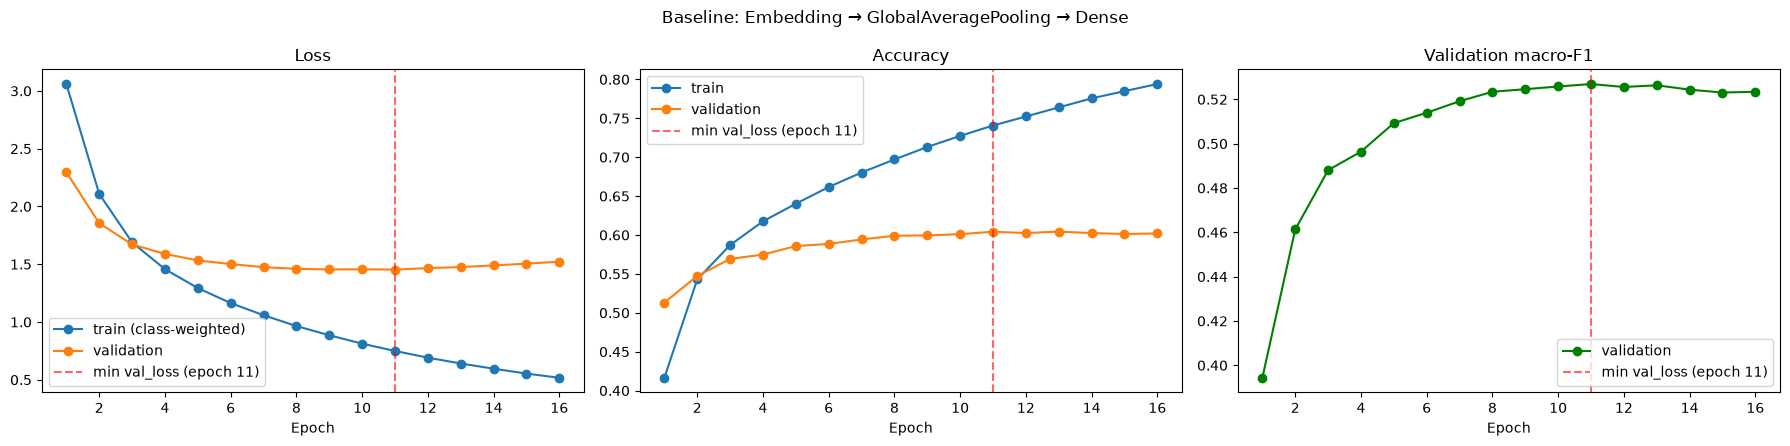

In [55]:
hist = pd.DataFrame(history.history)
hist["val_macro_f1"] = f1_cb.scores
hist.index = np.arange(1, len(hist) + 1)
hist.index.name = "epoch"
best_epoch = int(hist["val_loss"].idxmin())
display(hist.round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(hist.index, hist["loss"], marker="o", label="train (class-weighted)")
axes[0].plot(hist.index, hist["val_loss"], marker="o", label="validation")
axes[0].set_title("Loss")
axes[1].plot(hist.index, hist["accuracy"], marker="o", label="train")
axes[1].plot(hist.index, hist["val_accuracy"], marker="o", label="validation")
axes[1].set_title("Accuracy")
axes[2].plot(hist.index, hist["val_macro_f1"], marker="o", color="green", label="validation")
axes[2].set_title("Validation macro-F1")
for ax in axes:
    ax.axvline(best_epoch, color="red", linestyle="--", alpha=0.6, label=f"min val_loss (epoch {best_epoch})")
    ax.set_xlabel("Epoch")
    ax.legend()
plt.suptitle("Baseline: Embedding → GlobalAveragePooling → Dense")
plt.tight_layout()
plt.show()

**P4.4 Metrics:** Validation scores and per-class F1.

,baseline (validation only)
model,Embedding(64) -> GlobalAveragePooling1D -> Dropout(0.3) -> Dense(softmax)
trainable_params,1922340
vocab_size,30000
max_len,58
batch_size,128
learning_rate,0.001
class_weight,balanced
epochs_trained,16
best_epoch_min_val_loss,11
training_time,00:04:19


,precision,recall,f1-score,support
FIFTY,0.179,0.374,0.242,139
GOOD NEWS,0.249,0.379,0.300,140
IMPACT,0.316,0.377,0.343,345
EDUCATION,0.262,0.505,0.345,101
WORLD NEWS,0.282,0.454,0.348,218
WOMEN,0.292,0.448,0.354,339
ENVIRONMENT,0.326,0.424,0.368,132
WEIRD NEWS,0.363,0.401,0.381,267
TASTE,0.327,0.469,0.385,209
LATINO VOICES,0.300,0.558,0.390,113


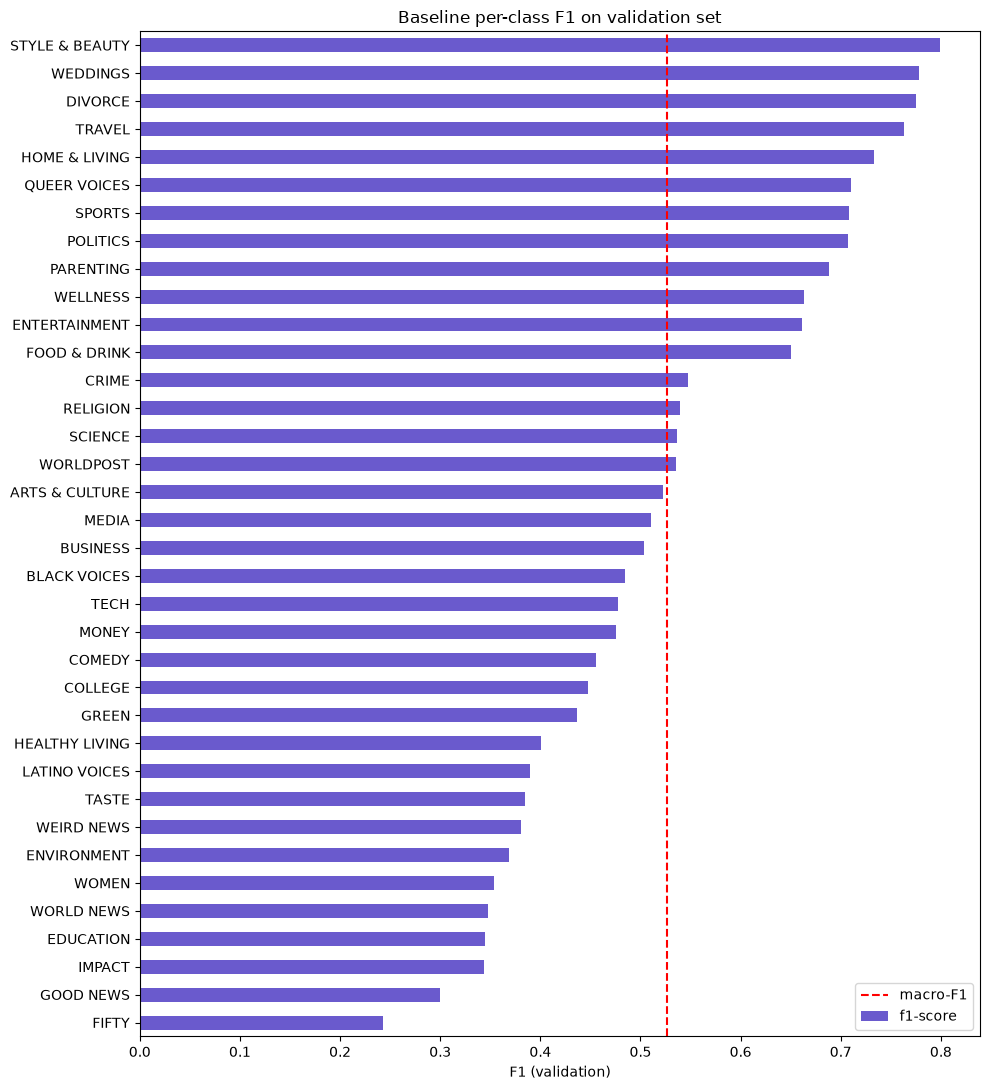

In [56]:
val_probs = baseline.predict(val_ds, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
val_true = val_df["label"].values

baseline_summary = {
    "model": "Embedding(64) -> GlobalAveragePooling1D -> Dropout(0.3) -> Dense(softmax)",
    "trainable_params": int(baseline.count_params()),
    "vocab_size": VOCAB_SIZE,
    "max_len": MAX_LEN,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "class_weight": "balanced",
    "epochs_trained": int(len(hist)),
    "best_epoch_min_val_loss": best_epoch,
    "training_time": format_hms(train_seconds),
    "val_loss_at_best": round(float(hist.loc[best_epoch, "val_loss"]), 4),
    "val_accuracy_at_best": round(float(accuracy_score(val_true, val_pred)), 4),
    "val_macro_f1_at_best": round(float(f1_score(val_true, val_pred, average="macro")), 4),
    "val_weighted_f1_at_best": round(float(f1_score(val_true, val_pred, average="weighted")), 4),
    "val_top3_accuracy": round(float(np.mean([t in np.argsort(p)[-3:] for t, p in zip(val_true, val_probs)])), 4),
}
display(pd.Series(baseline_summary).to_frame("baseline (validation only)"))

per_class = pd.DataFrame(classification_report(val_true, val_pred, target_names=class_names, output_dict=True, zero_division=0)).T
per_class = per_class.loc[class_names].sort_values("f1-score")
per_class["support"] = per_class["support"].astype(int)
display(per_class.round(3))

fig, ax = plt.subplots(figsize=(10, 11))
per_class["f1-score"].plot.barh(ax=ax, color="slateblue")
ax.axvline(baseline_summary["val_macro_f1_at_best"], color="red", linestyle="--", label="macro-F1")
ax.set_xlabel("F1 (validation)")
ax.set_title("Baseline per-class F1 on validation set")
ax.legend()
plt.tight_layout()
plt.show()

**P4.5 Confusion matrix:** Most frequent misclassifications.

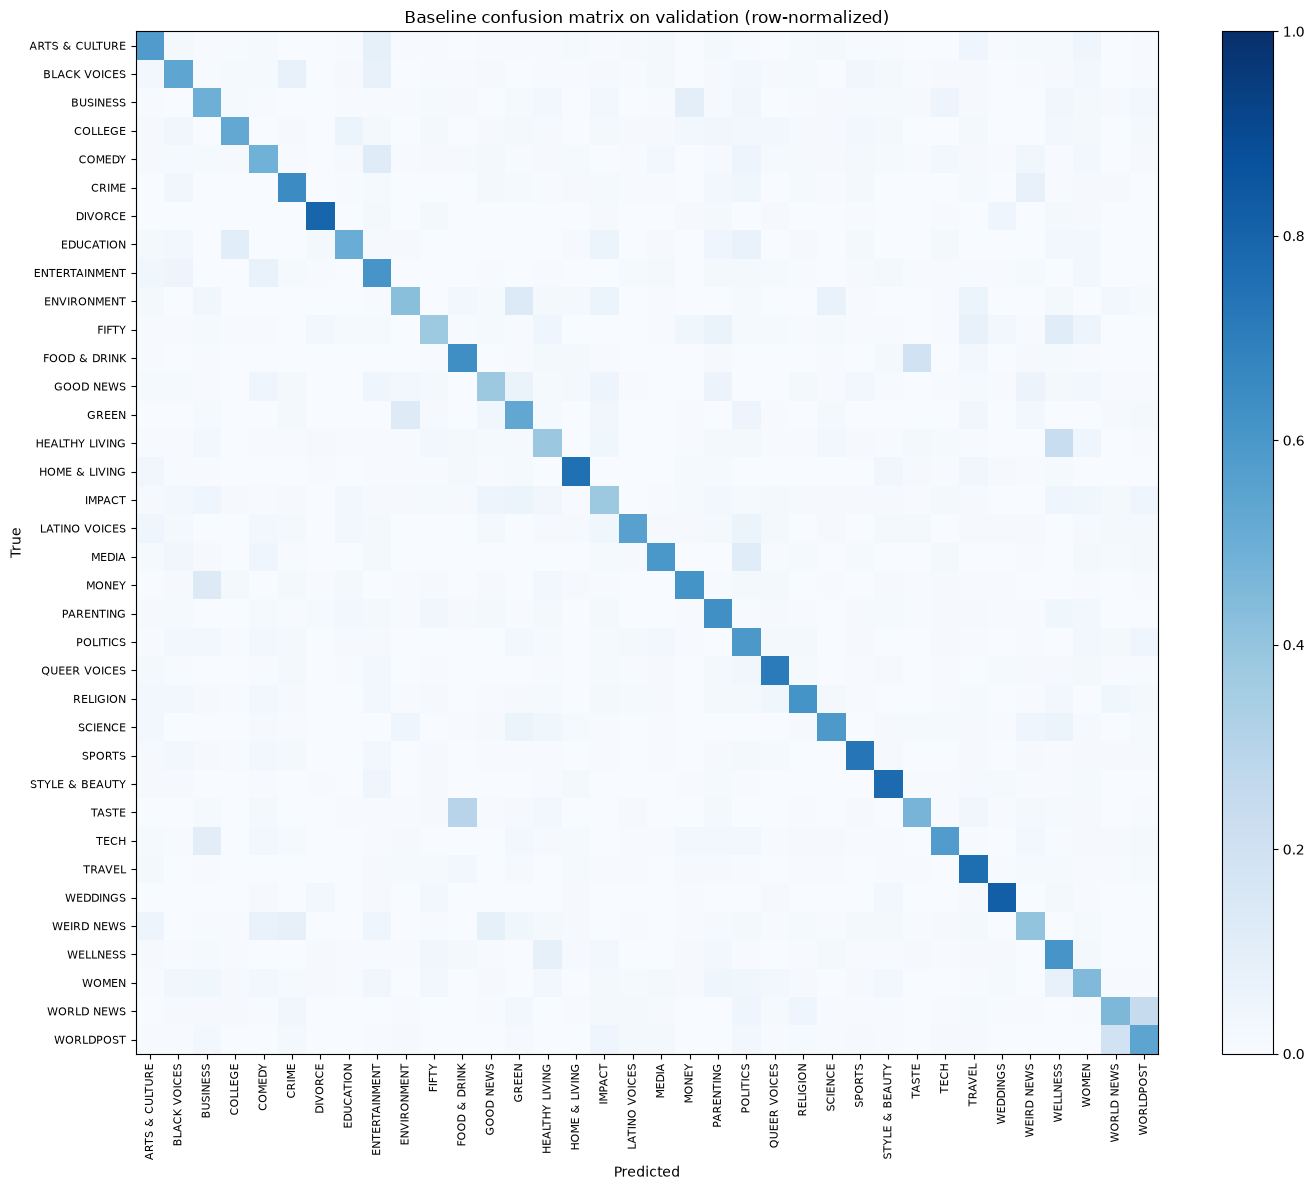

,true,predicted,count,share_of_true_class
0,HEALTHY LIVING,WELLNESS,156,0.234
1,WELLNESS,HEALTHY LIVING,152,0.085
2,POLITICS,WORLDPOST,132,0.040
3,WORLDPOST,WORLD NEWS,117,0.188
4,FOOD & DRINK,TASTE,117,0.188
5,ENTERTAINMENT,COMEDY,110,0.069
6,POLITICS,MEDIA,100,0.031
7,POLITICS,BUSINESS,95,0.029
8,POLITICS,GREEN,83,0.025
9,ENTERTAINMENT,BLACK VOICES,81,0.050


In [57]:
cm = confusion_matrix(val_true, val_pred, labels=np.arange(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(class_names, rotation=90, fontsize=8)
ax.set_yticklabels(class_names, fontsize=8)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Baseline confusion matrix on validation (row-normalized)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

off = cm.copy()
np.fill_diagonal(off, 0)
top_conf = [(class_names[i], class_names[j], int(off[i, j]), round(float(cm_norm[i, j]), 3))
            for i, j in zip(*np.unravel_index(np.argsort(off, axis=None)[::-1][:15], off.shape))]
display(pd.DataFrame(top_conf, columns=["true", "predicted", "count", "share_of_true_class"]))

**P4.6 Save results:** Save model and metrics.

In [58]:
os.makedirs("artifacts", exist_ok=True)
baseline.save("artifacts/baseline_model.keras")
hist.to_csv("artifacts/baseline_history.csv")
per_class.to_csv("artifacts/baseline_val_per_class.csv")
with open("artifacts/baseline_summary.json", "w") as f:
    json.dump(baseline_summary, f, indent=2)
print(os.listdir("artifacts"))

['baseline_summary.json', 'baseline_history.csv', 'baseline_model.keras', 'baseline_val_per_class.csv']


### Grading for Problem 4 (30 pts)

- **Implementation (18 pts):** a functional, appropriate baseline model; correct compilation and training; appropriate use of training and validation sets (no test evaluation); learning curves; and reproducible, clearly reported validation results.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual model, training behavior, and results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Model Architecture:**
   Describe your baseline model and justify why this structure suits your dataset.

In [59]:
# Your answer here, NOT in the next cell

a4a = """
The baseline is a bag of embeddings classifier. The 58 token IDs enter an Embedding layer that learns a 64 dimensional vector for each of the 30,000 words, 
with padding masked out. GlobalAveragePooling1D averages those vectors into one summary of the article, Dropout at 0.3 adds regularization, 
and a Dense softmax layer outputs probabilities over the 36 classes. It is trained with Adam at a 1e-3 learning rate, sparse categorical cross-entropy, 
batches of 128 and balanced class weights. Of the 1,922,340 parameters, all but 2,340 live in the embedding. Why does this suit the data? A news section is 
mostly signaled by which words appear, since "recipe" or "senate" says a lot on its own, and it trains in about 15 seconds per epoch on my CPU. 
What it cannot do matters just as much: it ignores word order entirely, so "not good" and "good not" look identical.
"""

In [60]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
The baseline is a bag of embeddings classifier. The 58 token IDs enter an Embedding layer that learns a 64 dimensional vector for each of the 30,000 words, 
with padding masked out. GlobalAveragePooling1D averages those vectors into one summary of the article, Dropout at 0.3 adds regularization, 
and a Dense softmax layer outputs probabilities over the 36 classes. It is trained with Adam at a 1e-3 learning rate, sparse categorical cross-entropy, 
batches of 128 and balanced class weights. Of the 1,922,340 parameters, all but 2,340 live in the embedding. Why does this suit the data? A news section is 
mostly signaled by which words appear, since "recipe" or "senate" says a lot on its own, and it trains in about 15 seconds per epoch on my CPU. 
What it cannot do matters just as much: it ignores word order entirely, so "not good" and "good not" look identical.



B. **Training Behavior:**
   Summarize the model’s training and validation curves. What trends did you observe?

In [61]:
# Your answer here, NOT in the next cell

a4b = """
Training ran for 16 epochs before early stopping stepped in, and the restored weights come from epoch 11, the minimum validation loss at 1.4536. 
Training accuracy climbed steadily from 0.416 to 0.794, while validation accuracy started at 0.513 and plateaued around 0.60 from epoch 8 onward. 
After epoch 11, validation loss turned and climbed back to 1.52 while training loss kept falling, which is overfitting caught in the act, ending with a train 
versus validation accuracy gap of about 0.19. Macro-F1 followed the same shape, leveling off near 0.527, and the whole run took 4 minutes 8 seconds. 
Two subtleties are worth noting. The training loss is class weighted, so its scale is not directly comparable to validation loss. And validation accuracy kept 
inching up to 0.6044 at epoch 13 even as validation loss rose, meaning the model was becoming overconfident on the articles it got wrong.
"""

In [62]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
Training ran for 16 epochs before early stopping stepped in, and the restored weights come from epoch 11, the minimum validation loss at 1.4536. 
Training accuracy climbed steadily from 0.416 to 0.794, while validation accuracy started at 0.513 and plateaued around 0.60 from epoch 8 onward. 
After epoch 11, validation loss turned and climbed back to 1.52 while training loss kept falling, which is overfitting caught in the act, ending with a train 
versus validation accuracy gap of about 0.19. Macro-F1 followed the same shape, leveling off near 0.527, and the whole run took 4 minutes 8 seconds. 
Two subtleties are worth noting. The training loss is class weighted, so its scale is not directly comparable to validation loss. And validation accuracy kept 
inching up to 0.6044 at epoch 13 even as validation loss rose, meaning the model was becoming overconfident on the articles it got wrong.



 C. **Baseline Metrics:**
   Report validation metrics only. What does this performance tell you about dataset difficulty?

In [63]:
# Your answer here, NOT in the next cell

a4c = """
On validation, the baseline reaches 0.604 accuracy, 0.527 macro-F1, 0.617 weighted F1 and 0.836 top-3 accuracy. Is that good? Against always guessing POLITICS at 16.3%, 
or random guessing at 2.8%, it is far from lazy, but the gap between macro and weighted F1 says the small classes are struggling. The best sections, 
STYLE & BEAUTY at 0.80, WEDDINGS and DIVORCE at 0.78, and TRAVEL at 0.76, all have distinctive vocabularies. The worst are FIFTY at 0.24, GOOD NEWS at 0.30, 
IMPACT at 0.34, and EDUCATION and WORLD NEWS at 0.35. Tellingly, the top confusions, HEALTHY LIVING to WELLNESS at 23%, WORLDPOST to WORLD NEWS and FOOD & DRINK to TASTE at 19%, 
are the exact pairs the EDA flagged. With the right answer in the top three 83.6% of the time, most errors are near misses, so the difficulty comes from label 
ambiguity more than model failure.
"""

In [64]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4c = {a4c}")

a4c = 
On validation, the baseline reaches 0.604 accuracy, 0.527 macro-F1, 0.617 weighted F1 and 0.836 top-3 accuracy. Is that good? Against always guessing POLITICS at 16.3%, 
or random guessing at 2.8%, it is far from lazy, but the gap between macro and weighted F1 says the small classes are struggling. The best sections, 
STYLE & BEAUTY at 0.80, WEDDINGS and DIVORCE at 0.78, and TRAVEL at 0.76, all have distinctive vocabularies. The worst are FIFTY at 0.24, GOOD NEWS at 0.30, 
IMPACT at 0.34, and EDUCATION and WORLD NEWS at 0.35. Tellingly, the top confusions, HEALTHY LIVING to WELLNESS at 23%, WORLDPOST to WORLD NEWS and FOOD & DRINK to TASTE at 19%, 
are the exact pairs the EDA flagged. With the right answer in the top three 83.6% of the time, most errors are near misses, so the difficulty comes from label 
ambiguity more than model failure.



  D. **Reflection:**
   What are the main limitations of your baseline? Which specific improvements (depth, regularization, pretraining) would you try next?
  

In [65]:
# Your answer here, NOT in the next cell

a4d = """
The baseline's main limitation is that it reads an article as a bag of words. It ignores order and context, so "North Korea" is just two separate words. 
It also overfits after epoch 11 with only dropout as regularization, its 30,000 word cap leaves 2.89% of validation tokens unknown, and its embeddings are 
learned from scratch on 160,097 examples. For the final project I would test three things. A custom 1D CNN or BiLSTM with spatial dropout, AdamW weight decay 
and a learning rate scheduler should capture phrases and reduce the WORLDPOST versus WORLD NEWS confusion. A pretrained DistilBERT, frozen first and then fine-tuned on a Colab GPU, 
should bring language knowledge the baseline lacks. And merging the three remaining renamed pairs should lift macro-F1, with the baseline rerun on the new labels. 
Every comparison will use the same validation split and macro-F1.
"""

In [66]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4d = {a4d}")

a4d = 
The baseline's main limitation is that it reads an article as a bag of words. It ignores order and context, so "North Korea" is just two separate words. 
It also overfits after epoch 11 with only dropout as regularization, its 30,000 word cap leaves 2.89% of validation tokens unknown, and its embeddings are 
learned from scratch on 160,097 examples. For the final project I would test three things. A custom 1D CNN or BiLSTM with spatial dropout, AdamW weight decay 
and a learning rate scheduler should capture phrases and reduce the WORLDPOST versus WORLD NEWS confusion. A pretrained DistilBERT, frozen first and then fine-tuned on a Colab GPU, 
should bring language knowledge the baseline lacks. And merging the three remaining renamed pairs should lift macro-F1, with the baseline rerun on the new labels. 
Every comparison will use the same validation split and macro-F1.



## Final checks and AI-use disclosure (read but not graded)

**AI question:** Describe what use you made of generative AI tools in preparing this milestone, consistent with CDS policy. Include what you used the tools for and how you verified the results.

**Your answer here:**

### Submission checklist

- [ ] I explored both datasets, chose one, and removed the unused dataset’s starter section.
- [ ] The submitted notebook has my name and answers to Problems 1–4.
- [ ] The notebook contains the code, relevant outputs, plots, and training/validation metrics for the baseline.
- [ ] The test set was created but **not used to make modeling decisions or report baseline test performance**.
- [ ] I restarted the kernel and ran the notebook from top to bottom, without errors.
- [ ] I documented random seeds, dataset sampling, dependencies, and AI-tool use.


## Appendix: A quick guide to Hugging Face Datasets

#### 1) What are they?

* A **table-like** dataset: rows = examples, columns = named fields (e.g., `"image"`, `"label"`, `"headline"`).
* Backed by **Apache Arrow** → fast, memory-efficient, lazy transforms.
* Two core objects:

  * `Dataset` — one table of rows/columns.
  * `DatasetDict` — a dict of splits, e.g. `{"train": Dataset, "val": Dataset, "test": Dataset}`.


#### 2) Load and inspect

```python
from datasets import load_dataset

# Food-101 (images)
food = load_dataset("food101", split="train+validation")  # both splits at once
len(food), food.column_names, food.features
# -> (≈101000, ['image','label'], {'label': ClassLabel(num_classes=101, names=[...])})

# Access by name (not by numeric column index!)
row0 = food[0]
img0, y0 = row0["image"], row0["label"]     # PIL image, int id
label_names = food.features["label"].names
label_names[y0]
```

For text (HuffPost JSON mirror):

```python
url = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff = load_dataset("json", data_files=url, split="train")
huff.column_names  # e.g. ['headline','short_description','category','authors','link','date']
```


#### 3) Common transforms

`Dataset`s are **immutable**: ops return a new dataset.

* **Map** (add/modify columns):

```python
def mk_text(ex):
    h = (ex.get("headline") or "").strip()
    s = (ex.get("short_description") or "").strip()
    return {"text": (h + " [SEP] " + s).strip()}

huff = huff.map(mk_text)  # adds 'text' column
```

* **Class-encode** labels (strings → integers with a vocabulary):

```python
from datasets.features import ClassLabel
if not isinstance(huff.features["category"], ClassLabel):
    huff = huff.class_encode_column("category")  # now ints with .names
```

* **Filter / select / rename / drop**:

```python
small = huff.select(range(5000))  # first 5k rows
huff = huff.remove_columns(["authors","link","date"])
huff = huff.rename_column("category", "label")
```


#### 4) Splitting & shuffling

```python
# Stratified 80/10/10 on Food-101 by 'label'
from datasets import DatasetDict
label_col = "label"

tmp = food.train_test_split(test_size=0.10, seed=42, stratify_by_column=label_col)
train_val = tmp["train"].train_test_split(test_size=1/9, seed=42, stratify_by_column=label_col)
ds = DatasetDict(train=train_val["train"], val=train_val["test"], test=tmp["test"])

len(ds["train"]), len(ds["val"]), len(ds["test"])
```

* `train_test_split` is **random by default** (reproducible with `seed=`).
* You typically **don’t need to pre-shuffle** datasets if your training dataloader already shuffles each epoch.


#### 5) Working with images

Use `with_transform` to apply on-the-fly resizing/augmentation and return tensors:

```python
import torchvision.transforms as T
from torch.utils.data import DataLoader
import torch, math, random

IM_SIZE = 224
train_tfms = T.Compose([T.RandomResizedCrop(IM_SIZE), T.RandomHorizontalFlip(), T.ToTensor()])
eval_tfms  = T.Compose([T.Resize(256), T.CenterCrop(IM_SIZE), T.ToTensor()])

def add_pixel_values(ex, tfms):  # ex['image'] -> ex['pixel_values']
    ex = dict(ex); ex["pixel_values"] = tfms(ex["image"]); return ex

train_t = ds["train"].with_transform(lambda ex: add_pixel_values(ex, train_tfms))
val_t   = ds["val"].with_transform(lambda ex: add_pixel_values(ex, eval_tfms))

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["label"] for b in batch])}

train_loader = DataLoader(train_t, batch_size=64, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_t,   batch_size=64, shuffle=False, collate_fn=collate)
```

### 6) Working with Text

You can preprocess and tokenize text datasets using either a **transformer tokenizer** or a **linguistic pipeline like spaCy**, depending on your model type and goals.


#### Option A: Transformer Tokenizer (for fine-tuning models like BERT or DistilBERT)

Use a pretrained tokenizer with the Hugging Face `map` method to efficiently process your dataset in batches:

```python
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=128)

tokenized = huff.map(
    tokenize,
    batched=True,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

This produces token IDs, attention masks, and other fields expected by transformer models.
Use this approach if your project involves fine-tuning pretrained language models.


#### Option B: spaCy Tokenization and Cleaning (for classical ML or custom preprocessing)

If you are **not using transformers**, or if you want to explore feature engineering (e.g., TF-IDF, word frequency, or embedding averages), you can preprocess text with **spaCy** instead.

```python
# !pip install spacy
# !python -m spacy download en_core_web_sm

import spacy
from datasets import load_dataset

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "textcat"])
STOP = spacy.lang.en.stop_words.STOP_WORDS

def spacy_clean(batch):
    docs = list(nlp.pipe(batch["text"], batch_size=1000))
    cleaned = []
    for doc in docs:
        tokens = [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
        cleaned.append(" ".join(tokens))
    return {"text_clean": cleaned, "len_tokens": [len(c.split()) for c in cleaned]}

huff = huff.map(
    spacy_clean,
    batched=True,
    batch_size=1000,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

The resulting column `text_clean` can be used with:

* `TfidfVectorizer` (Scikit-learn)
* `TextVectorization` (Keras)
* or any other custom embedding method.

> 💡 **Tip:** spaCy is ideal for lightweight NLP pipelines or for models that rely on explicit preprocessing (lemmatization, stopword removal). Transformer tokenizers, by contrast, expect *raw text* and handle subword tokenization internally.



#### 7) Slicing, concatenating, saving

```python
# Slicing
head_1000 = food.select(range(1000))
tail_10pct = food.select(range(int(0.9*len(food)), len(food)))

# Concatenate splits/datasets
from datasets import concatenate_datasets
all_train = concatenate_datasets([ds["train"], ds["val"]])

# Save / reload
ds.save_to_disk("food101_splits")
from datasets import load_from_disk
ds2 = load_from_disk("food101_splits")
```


#### 8) Quick “gotchas”

* **Columns by name** (strings), not numeric indices.
* Avoid converting huge columns to `list(...)` unless necessary; prefer vectorized ops with `map`, `filter`, `select`.
* `PYTHONHASHSEED` must be set **before** the Python process starts to matter; use explicit `seed=` arguments for reproducibility.
* Datasets print **previews** (e.g., `Column([6, 6, 6, ...])` is just the first few values).


#### 9) A minimal checklist to follow

1. `load_dataset(...)` → confirm `column_names`, `features`.
2. Build any needed columns (`"text"`), and **class-encode** labels if strings.
3. Make a **stratified 80/10/10** split (`train_test_split` ×2).
4. Do **EDA**: class counts, sample printouts or image grids.
5. For training:

   * **images** → `with_transform` + DataLoader
   * **text** → tokenizer via `.map(...)` + trainer/model pipeline
6. Save your `DatasetDict` with `save_to_disk(...)` (optional for text but handy, **don't** use it for big image datasets).

